# subgraphsearch quickstart

`subgraphsearch` finds [induced subgraphs](https://en.wikipedia.org/wiki/Induced_subgraph) with a given number of vertices and edges,
or a given total weight in a weighted graph: $k$ items whose pairwise scores add up to a target, or to as much
as it can reach. The same search finds induced [cycles](https://en.wikipedia.org/wiki/Cycle_(graph_theory)), [paths](https://en.wikipedia.org/wiki/Induced_path),
[trees](https://en.wikipedia.org/wiki/Tree_(graph_theory)) and [cliques](https://en.wikipedia.org/wiki/Clique_(graph_theory)), and [regular](https://en.wikipedia.org/wiki/Regular_graph) and
connected subgraphs. The method is a randomized [tabu search](https://en.wikipedia.org/wiki/Tabu_search).

The notebook starts with one dense random graph: exact edge counts, near misses, and how the search compares
with a general solver. It then turns to weighted graphs and choosing diverse items, a practical problem where
subgraphsearch reaches published best values in about a second, and to saving and tuning searches. Next come
shapes: regular subgraphs, cycles and trees, induced paths, cliques and independent sets. Then mathematics:
strongly regular graphs from switching and block designs, spectral bounds, Hadamard matrices, equiangular
lines and error-correcting codes. It ends with graph structure and file formats.

In [1]:
import subgraphsearch as ss
from subgraphsearch import viz

ss.__version__

'3.0.0'

## A graph

`ss.generate` makes random graphs; `"exponential"` is the [Erdős–Rényi](https://en.wikipedia.org/wiki/Erd%C5%91s%E2%80%93R%C3%A9nyi_model)
model, in which each pair of vertices is an edge with probability equal to the density. `ss.read` reads
graph6, sparse6, Matrix Market, edge lists and adjacency lists. In a notebook, a graph displays as a summary
with its degree distribution and, when it is small, a drawing.

In [2]:
g = ss.generate("exponential", 100, 0.6, seed=1)   # 100 vertices, density 0.6
g

vertices,100
edges,"2,969"
density,0.5998
components,1
degree min / mean / max,48 / 59.4 / 71


## Kinds of search

Every search picks $k$ vertices and swaps one of them for an outside vertex at each move, trying to drive a
*conflict* to 0. What the conflict measures depends on what you ask for:

| You want | Call | Conflict |
| --- | --- | --- |
| $k$ vertices spanning exactly $m$ edges | `ss.search(g, k, m)` | $\lvert e - m \rvert$, with $e$ the edges among them |
| $k$ vertices whose edges weigh $m$ in total | `ss.search(w, k, m)` on a `WeightedGraph` | $\lvert \text{weight} - m \rvert$ |
| a [$d$-regular](https://en.wikipedia.org/wiki/Regular_graph) subgraph on $k$ vertices | `ss.search(g, k, degree=d)` | $\sum_{v \in S} \lvert d_S(v) - d \rvert$ |
| the same, in two phases | `ss.search(g, k, degree=d, two_phase=True)` | first $\lvert e - kd/2 \rvert$, then regularity |
| any of these, connected | add `connected=True` | plus 1 for each component beyond the first |
| an [induced path](https://en.wikipedia.org/wiki/Induced_path) on $k$ vertices | `ss.search(g, k, path=True)` | $\lvert \text{deviation} - 2 \rvert + \lvert e - (k - 1) \rvert$, plus extra components |
| the same, from $s$ to $t$ | add `endpoints=(s, t)` | the same, for a path two vertices longer |

Here $d_S(v)$ is the number of neighbors $v$ has among the chosen vertices $S$. Any of these can also
require some vertices with `fixed=`, return near misses with `solutions(max_conflict=...)`, and record the
conflict after every move with `trace=True`. Edge-count and weight searches can also use `aspiration=True`,
which lets the search undo its last swap when that would beat the best conflict so far (the *aspiration
criterion* of a tabu search). The sections below try each one.

## A given number of edges

The basic search asks for $k$ vertices spanning exactly $m$ edges, here 30 vertices spanning 330. Each of the
40 *experiments* (independent restarts) reports the best subgraph it found.

In [3]:
basic = ss.search(g, size=30, edges=330)
basic

target,"30 vertices, with 330 edges"
experiments,40 × ≤250 moves
successes,40 (100%)
relative cost,15.7 moves
true cost,15.7 moves
average conflict,0.000
rng / seed,xoshiro / 1


`solutions()` lists the distinct vertex sets the experiments found, here a different one for each, and
`viz.plot_graph` draws one.

40 distinct solutions


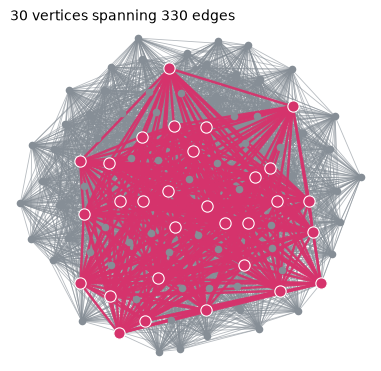

In [4]:
print(len(basic.solutions()), "distinct solutions")
viz.plot_graph(g, basic.best.vertices, title="30 vertices spanning 330 edges");

Some targets are harder. For 30 vertices of this graph, 346 edges is near the limit of what the search finds,
and it succeeds only some of the time. `trace=True` records the *conflict*, the distance from
the target edge count, after every move.

In [5]:
r = ss.search(g, size=30, edges=346, experiments=60, max_moves=2000, div_freq=300, div_dur=8, seed=5, trace=True)
print(r.summary())

41/60 experiments found a 30-vertex subgraph with 346 edges
relative cost 589.2 moves, true cost 1516.0 moves, average conflict 0.317


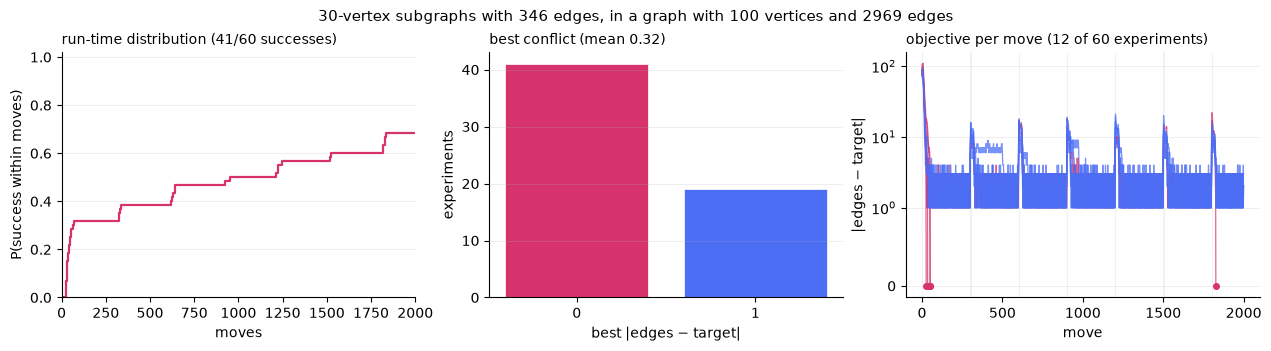

In [6]:
viz.plot_search_summary(r);

The **run-time distribution** (left) is the fraction of experiments that succeeded within a given number of
moves, the middle panel counts the best conflict each experiment reached, and the **traces** (right) show the
conflict after each move for some of the experiments. Here 19 of the 41 successes came within 100 moves, and
the rest in bursts just after moves 300, 600, 900 and so on, where each diversification cycle after the first
starts with a region kick (see Tuning). Without kicks, the rest of the 2000-move budget adds only two successes
to those first 19, so many short experiments beat a few long ones; with them, longer runs keep paying off.

Success falls off sharply around the limit: one edge fewer is found by every experiment, and a few more by
none.

In [7]:
settings = {"experiments": 60, "max_moves": 2000, "div_freq": 300, "div_dur": 8, "seed": 5}
{m: ss.search(g, 30, m, **settings).successes for m in (345, 346, 350)}

{345: 60, 346: 41, 350: 0}

## Near misses and approximate solutions

The search minimizes the conflict, so every experiment ends with the best subgraph it reached, even when it
misses the target. `solutions(max_conflict=c)` returns the distinct subgraphs within $c$ edges of the target
(`--max-conflict c` on the command line), and each one's conflict is exact: it is how far that subgraph's
edge count is from the target. This turns the search into an approximation algorithm:

- **When a target is out of reach,** the near misses are the closest subgraphs found. No experiment finds 30
  vertices spanning 350 edges, but several find 349.
- **To find the densest $k$ vertices,** aim at a target the graph cannot reach, such as all $k(k-1)/2$ edges,
  and take the best near miss: its edge count is the most the search found. Aiming at 0 edges finds the
  sparsest $k$ vertices the same way.

The search cannot show that nothing closer exists, so the best near miss is a lower bound on the true
optimum, not a proof of it.

In [8]:
near = ss.search(g, 30, 350, **settings).solutions(max_conflict=1)
print("within one edge of 350:", [g.induced_edge_count(vs) for vs in near])

densest = ss.search(g, 30, 30 * 29 // 2, **settings).best   # aim at a 30-clique
print("aiming at a 30-clique, the densest 30 vertices found span", g.induced_edge_count(densest.vertices), "edges")

within one edge of 350: [349, 349, 349]
aiming at a 30-clique, the densest 30 vertices found span 349 edges


## Compared with other methods

Finding $k$ vertices that span exactly $m$ edges has no specialist to compare with, so here subgraphsearch is set
beside a strong general solver: [CP-SAT](https://developers.google.com/optimization/cp/cp_solver) from
Google's OR-Tools, given one yes-or-no variable per vertex and the edge count as half the sum of the chosen
vertices' degrees inside the set (for a clique, the usual form, which forbids each pair of non-adjacent vertices,
is far better). These results were recorded separately, so that this notebook does not need OR-Tools: CP-SAT 9.15
on 16 cores, stopped after 10 seconds, and subgraphsearch with 60 experiments of up to 2,000 moves, on random graphs
of density 0.6 unless noted. The first four rows ask for the most edges subgraphsearch finds among 30% of the
vertices, in graphs of growing size. (Maximum cliques, which do have specialists, are compared with them in
the section on cliques.)

In [9]:
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

# Recorded: graph, target, search successes out of 60 (None: no solution exists), search ms,
# CP-SAT ms (None: nothing found in 10 s)
edge_runs = [
    ("30 vertices", "9 vertices, 33 edges", 60, 0.2, 180),
    ("50 vertices", "15 vertices, 91 edges", 60, 1.1, 8800),
    ("70 vertices", "21 vertices, 176 edges", 59, 3.4, None),
    ("100 vertices", "30 vertices, 346 edges", 25, 13, None),
    ("100 vertices", "30 vertices, 340 edges", 60, 1.0, None),
    ("50 vertices, density 0.5", "10 vertices, 22 edges", 60, 0.5, 8),
    ("100 vertices", "an 11-clique", 60, 0.7, 13),
    ("30 vertices", "9 vertices, 34 edges", None, None, 900),
]

def duration(ms):
    return f"{ms:g} ms" if ms < 100 else f"{ms / 1000:g} s"

lines = ["| Graph | Target | subgraphsearch: found / 60 | CP-SAT |", "| --- | --- | --- | --- |"]
for graph, target, hits, mine, theirs in edge_runs:
    if hits is None:
        lines.append(f"| {graph} | {target} | none (none can exist) | proved impossible in {duration(theirs)} |")
        continue
    cp = "nothing in 10 s" if theirs is None else f"found in {duration(theirs)}"
    lines.append(f"| {graph} | {target} | {hits}/60 in {duration(mine)} | {cp}{' (as a clique)' if 'clique' in target else ''} |")
display(Markdown("\n".join(lines)))

| Graph | Target | subgraphsearch: found / 60 | CP-SAT |
| --- | --- | --- | --- |
| 30 vertices | 9 vertices, 33 edges | 60/60 in 0.2 ms | found in 0.18 s |
| 50 vertices | 15 vertices, 91 edges | 60/60 in 1.1 ms | found in 8.8 s |
| 70 vertices | 21 vertices, 176 edges | 59/60 in 3.4 ms | nothing in 10 s |
| 100 vertices | 30 vertices, 346 edges | 25/60 in 13 ms | nothing in 10 s |
| 100 vertices | 30 vertices, 340 edges | 60/60 in 1 ms | nothing in 10 s |
| 50 vertices, density 0.5 | 10 vertices, 22 edges | 60/60 in 0.5 ms | found in 8 ms |
| 100 vertices | an 11-clique | 60/60 in 0.7 ms | found in 13 ms (as a clique) |
| 30 vertices | 9 vertices, 34 edges | none (none can exist) | proved impossible in 0.9 s |

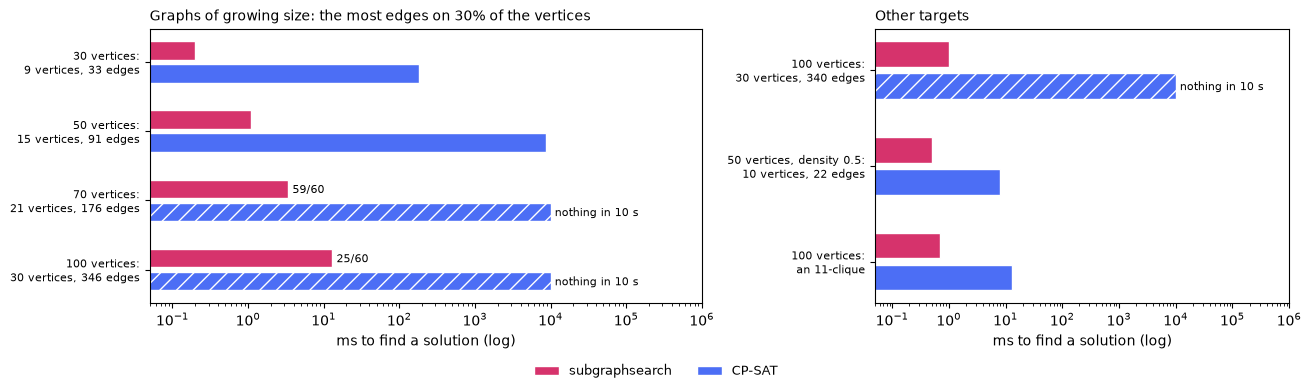

In [10]:
groups = [("Graphs of growing size: the most edges on 30% of the vertices", [0, 1, 2, 3]), ("Other targets", [4, 5, 6])]
methods = [("subgraphsearch", "#d6336c"), ("CP-SAT", "#4c6ef5")]
fig, axs = plt.subplots(1, 2, figsize=(13, 3.8), layout="constrained", sharex=True,
                        gridspec_kw={"width_ratios": [4, 3]})
for ax, (title, rows) in zip(axs, groups):
    for y, i in enumerate(rows):
        graph, target, hits, mine, theirs = edge_runs[i]
        for j, ((label, color), t) in enumerate(zip(methods, [mine, theirs or 10000])):
            capped = j == 1 and theirs is None
            ax.barh(3 * y + j, t, color=color, hatch="//" if capped else None, edgecolor="white",
                    label=label if (y, ax) == (0, axs[0]) else None)
            note = "nothing in 10 s" if capped else (f"{hits}/60" if j == 0 and hits < 60 else "")
            if note:
                ax.annotate(note, (t, 3 * y + j), xytext=(3, -3), textcoords="offset points", fontsize=8)
    ax.set_yticks([3 * y + 0.5 for y in range(len(rows))],
                  [f"{edge_runs[i][0]}:\n{edge_runs[i][1]}" for i in rows], fontsize=8)
    ax.invert_yaxis()
    ax.set_xscale("log")
    ax.set_xlim(0.05, 1e6)
    ax.set_title(title, fontsize=10, loc="left")
    ax.set_xlabel("ms to find a solution (log)")
fig.legend(loc="outside lower center", ncol=2, frameon=False, fontsize=9);

Measured on graphs from 20 to 59 vertices, with the same density and target, CP-SAT's time varies a lot from
graph to graph but grows steeply overall, and from 44 vertices on it mostly finds nothing within its 10 seconds,
while subgraphsearch's time stays flat, at about a millisecond or less:

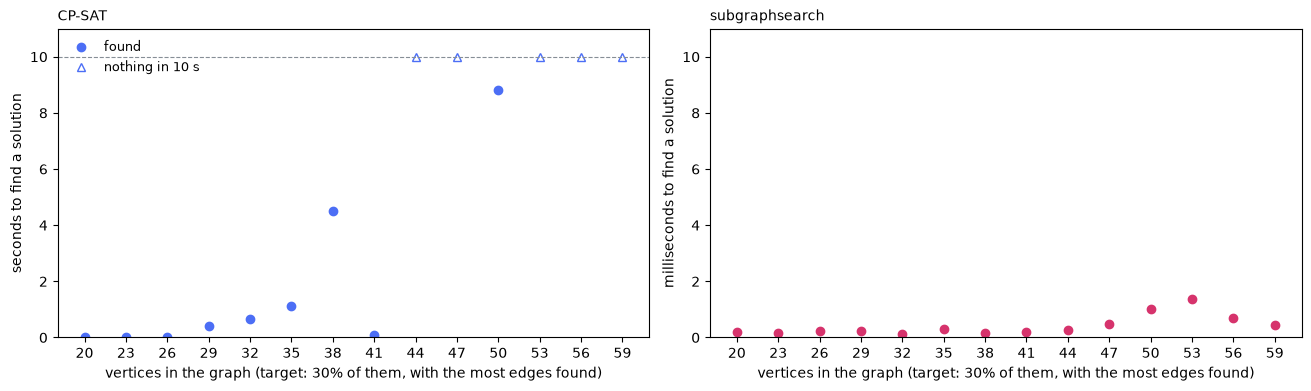

In [11]:
# Recorded: vertices, target vertices and edges, subgraphsearch successes / 60 and ms,
# CP-SAT ms (None: nothing found in 10 s)
scaling = [(20, 6, 15, 60, 0.20, 25), (23, 7, 20, 60, 0.17, 18), (26, 8, 28, 60, 0.23, 23),
           (29, 9, 34, 60, 0.22, 414), (32, 10, 43, 60, 0.14, 650), (35, 10, 42, 60, 0.29, 1125),
           (38, 11, 52, 60, 0.15, 4490), (41, 12, 60, 60, 0.19, 85), (44, 13, 70, 60, 0.25, None),
           (47, 14, 81, 60, 0.49, None), (50, 15, 91, 60, 1.00, 8814), (53, 16, 105, 60, 1.37, None),
           (56, 17, 116, 60, 0.70, None), (59, 18, 129, 60, 0.45, None)]
sizes = [row[0] for row in scaling]
done = [row for row in scaling if row[5]]
timed_out = [row for row in scaling if not row[5]]
fig, (cp, mine) = plt.subplots(1, 2, figsize=(13, 3.8), layout="constrained")
cp.plot([row[0] for row in done], [row[5] / 1000 for row in done], "o", color="#4c6ef5", label="found")
cp.plot([row[0] for row in timed_out], [10] * len(timed_out), "^", color="#4c6ef5", markerfacecolor="white",
        label="nothing in 10 s")
cp.axhline(10, color="#868e96", lw=0.8, ls="--")
cp.set_ylim(0, 11)
cp.set_ylabel("seconds to find a solution")
cp.set_title("CP-SAT", fontsize=10, loc="left")
cp.legend(frameon=False, fontsize=9, loc="upper left")
mine.plot(sizes, [row[4] for row in scaling], "o", color="#d6336c")
mine.set_ylim(0, 11)
mine.set_ylabel("milliseconds to find a solution")
mine.set_title("subgraphsearch", fontsize=10, loc="left")
for ax in (cp, mine):
    ax.set_xticks(sizes)
    ax.set_xlabel("vertices in the graph (target: 30% of them, with the most edges found)")

CP-SAT's time grows steeply with the graph, from a fifth of a second at 30 vertices to more than 10 seconds at 70,
while subgraphsearch stays at a few milliseconds: exact edge counts in graphs past a few dozen vertices are its
niche. What CP-SAT can do and subgraphsearch cannot is prove a target impossible, as in the last row, which
also shows that the 33 edges subgraphsearch found in the first row are the most possible. The two work well together:
subgraphsearch finds solutions fast, and on small graphs a solver can confirm that nothing better exists.

## Weighted graphs

In a `WeightedGraph` every edge has an integer weight, and the target is the total weight of the subgraph's
edges. This graph has 200 vertices and a mean weight of 0.65 per pair of vertices; the search looks for 15
vertices whose edges weigh 140 in total. The next section puts weights to a practical use.

In [12]:
w = ss.generate_weighted(200, 0.65, seed=1)
ss.search(w, 15, 140, experiments=40, max_moves=3000, div_freq=300, div_dur=10)

target,"15 vertices, with total weight 140"
experiments,40 × ≤3000 moves
successes,40 (100%)
relative cost,23.4 moves
true cost,23.4 moves
average conflict,0.000
rng / seed,xoshiro / 1


## Choosing diverse items

Many practical choices come down to picking $k$ items out of $n$ so that the chosen ones are as different from
each other as possible: a diverse portfolio, sites for facilities that should be far apart, a varied set of
compounds to test, a jury. Given a distance between every two items, this is the
[maximum diversity problem](https://grafo.etsii.urjc.es/optsicom/mdp.html):
maximize the sum of the distances between the chosen items. With the items as vertices and the distances as
edge weights, that sum is the total weight of an induced subgraph on $k$ vertices, which is what a weighted
search aims at.

The problem has a standard benchmark, MDPLIB (Martí, Gallego and Duarte, 2010), with best known values from
two-hour runs of a scatter search made for the problem. Its SOM-b instances have integer distances from 0 to 9
between every two items. Eight of them, with 100 to 400 items, are in `examples/data/mdplib` (under their own
license, Creative Commons Attribution). Below, subgraphsearch aims at each best known value with the same
settings for every instance, once without *region kicks* (`kick_size=0`) and once with large ones
(`kick_size=16`). A region kick starts each diversification cycle after the first by rebuilding the part of
the selection nearest a random item; searches use small kicks of 4 by default (more under Tuning).
Beside it is CP-SAT, maximizing the sum of the distances, from separately recorded runs stopped after 10
seconds, with the best value it found and the upper bound it proved.

In [13]:
import time
import urllib.request
from pathlib import Path

mdp_local = Path("examples/data/mdplib")
mdp_url = "https://raw.githubusercontent.com/vglazer/subgraphsearch/main/examples/data/mdplib/"
# instance, best known value, and CP-SAT's best value and proved upper bound after 10 s (recorded)
diversity = [("SOM-b_1_n100_m10", 333, 329, 390), ("SOM-b_2_n100_m20", 1195, 1171, 1594),
             ("SOM-b_3_n100_m30", 2457, 2457, 3452), ("SOM-b_4_n100_m40", 4142, 4127, 5822),
             ("SOM-b_6_n200_m40", 4450, 4263, 6662), ("SOM-b_10_n300_m60", 9689, 9297, 15165),
             ("SOM-b_13_n400_m40", 4658, 4374, 7020), ("SOM-b_14_n400_m80", 16956, 15595, 27085)]

def read_mdplib(name):
    """An MDPLIB instance as a weighted graph, and the number of items to pick."""
    path = mdp_local / f"{name}.txt"
    text = path.read_text() if path.exists() else urllib.request.urlopen(mdp_url + f"{name}.txt", timeout=30).read().decode()
    first, *rest = text.splitlines()
    n, k = map(int, first.split())
    pairs = [tuple(map(int, line.split())) for line in rest if line.strip()]
    return ss.WeightedGraph(n, [(u, v, d) for u, v, d in pairs if d]), k

def diversity_run(items, k, target, kick_size):
    """Successes out of 60 and milliseconds taken."""
    start = time.perf_counter()
    found = ss.search(items, k, target, experiments=60, max_moves=20000, div_freq=300, div_dur=10, kick_size=kick_size)
    return found.successes, 1000 * (time.perf_counter() - start)

mdp_rows = []
try:
    for name, best_known, cp_best, cp_bound in diversity:
        items, k = read_mdplib(name)
        mdp_rows.append((items.n, k, best_known, diversity_run(items, k, best_known, 0),
                         diversity_run(items, k, best_known, 16), cp_best, cp_bound))
except OSError as error:
    print("could not read the benchmark instances, so this comparison is skipped:", error)

lines = ["| Items | Chosen | Best known | subgraphsearch, `kick_size=0`: found / 60 | `kick_size=16` | CP-SAT after 10 s: best (upper bound) |",
         "| --- | --- | --- | --- | --- | --- |"]
for n, k, best_known, (plain_hits, plain_ms), (kick_hits, kick_ms), cp_best, cp_bound in mdp_rows:
    lines.append(f"| {n} | {k} | {best_known:,} | {plain_hits}/60 in {plain_ms:.0f} ms | {kick_hits}/60 in {kick_ms:.0f} ms "
                 f"| {cp_best:,} ({cp_bound:,}) |")
display(Markdown("\n".join(lines)))

| Items | Chosen | Best known | subgraphsearch, `kick_size=0`: found / 60 | `kick_size=16` | CP-SAT after 10 s: best (upper bound) |
| --- | --- | --- | --- | --- | --- |
| 100 | 10 | 333 | 60/60 in 2 ms | 60/60 in 2 ms | 329 (390) |
| 100 | 20 | 1,195 | 60/60 in 18 ms | 60/60 in 16 ms | 1,171 (1,594) |
| 100 | 30 | 2,457 | 57/60 in 56 ms | 60/60 in 10 ms | 2,457 (3,452) |
| 100 | 40 | 4,142 | 59/60 in 38 ms | 60/60 in 3 ms | 4,127 (5,822) |
| 200 | 40 | 4,450 | 6/60 in 416 ms | 56/60 in 183 ms | 4,263 (6,662) |
| 300 | 60 | 9,689 | 4/60 in 899 ms | 59/60 in 424 ms | 9,297 (15,165) |
| 400 | 40 | 4,658 | 0/60 in 1190 ms | 39/60 in 702 ms | 4,374 (7,020) |
| 400 | 80 | 16,956 | 1/60 in 1595 ms | 41/60 in 1108 ms | 15,595 (27,085) |

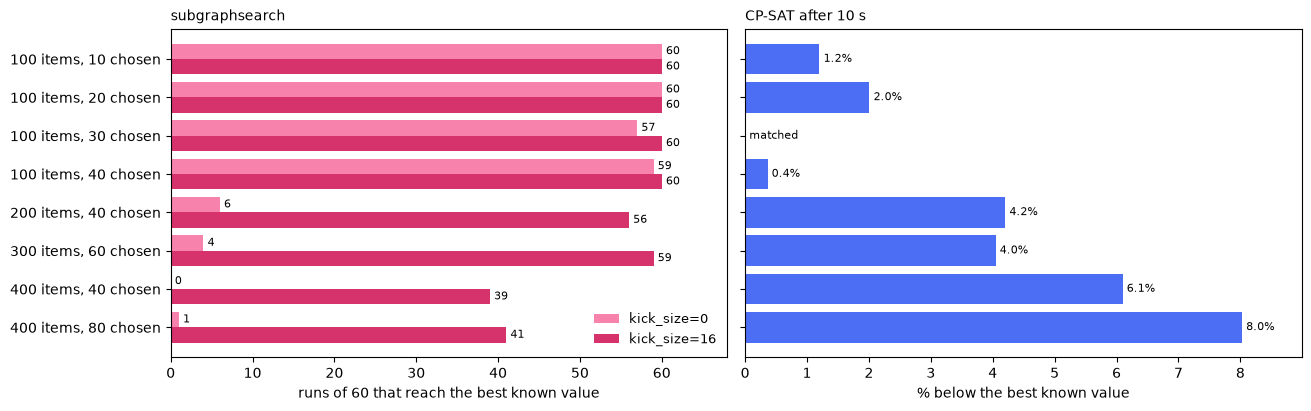

In [14]:
if mdp_rows:
    labels = [f"{n} items, {k} chosen" for n, k, *_ in mdp_rows]
    ys = range(len(mdp_rows))
    fig, (mine_ax, cp_ax) = plt.subplots(1, 2, figsize=(13, 4), layout="constrained", sharey=True)
    for offset, column, label, color in ((-0.2, 3, "kick_size=0", "#f783ac"), (0.2, 4, "kick_size=16", "#d6336c")):
        hits = [row[column][0] for row in mdp_rows]
        mine_ax.barh([y + offset for y in ys], hits, height=0.4, color=color, label=label)
        for y, h in zip(ys, hits):
            mine_ax.annotate(str(h), (h, y + offset), xytext=(3, 0), textcoords="offset points", va="center", fontsize=8)
    mine_ax.set_yticks(list(ys), labels)
    mine_ax.set_xlim(0, 68)
    mine_ax.set_xlabel("runs of 60 that reach the best known value")
    mine_ax.set_title("subgraphsearch", fontsize=10, loc="left")
    mine_ax.legend(frameon=False, fontsize=9, loc="lower right")
    shortfall = [100 * (row[2] - row[5]) / row[2] for row in mdp_rows]
    cp_ax.barh(list(ys), shortfall, color="#4c6ef5")
    for y, s in zip(ys, shortfall):
        cp_ax.annotate("matched" if s == 0 else f"{s:.1f}%", (s, y), xytext=(3, 0), textcoords="offset points",
                       va="center", fontsize=8)
    cp_ax.set_xlim(0, 1.12 * max(shortfall))
    cp_ax.set_xlabel("% below the best known value")
    cp_ax.set_title("CP-SAT after 10 s", fontsize=10, loc="left")
    mine_ax.invert_yaxis()

Without kicks, subgraphsearch reaches every best known value up to 300 items but finds the larger instances
harder, and on the 400-item ones a run rarely gets there, if ever. With large kicks, most runs reach the best
known value on every instance, in about a second or less for 60 runs. CP-SAT, in 10 seconds, reaches one of them and
falls further short as the instances grow, by about 8% on the largest; the upper bounds it proves are far above
the best values, so it cannot show that any of them is optimal. The strongest methods for this problem include
iterated tabu search (Palubeckis, 2007), which alternates a tabu search with perturbations. subgraphsearch, a
port of programs written in 2002, combines tabu moves with diversification in much the same way, for any
target. Choosing $k$ items for a target total of pairwise scores is the kind of problem subgraphsearch is for:
a practical one, which solvers are used for, where its search is fast and needs little tuning.

## Saving and repeating results

`result.save(path)` writes a result as JSON, and `ss.SearchResult.load(path, g)` reads it back given the
graph. Results depend only on the seed and the settings, not on the number of threads, so a search can be
repeated exactly; change the seed for independent runs.

In [15]:
import pathlib
import tempfile

result = ss.search(g, 30, 330, experiments=8, seed=2)
path = pathlib.Path(tempfile.mkdtemp()) / "result.json"
result.save(path)
assert ss.SearchResult.load(path, g).solutions() == result.solutions()
print("the same seed gives the same solutions:", ss.search(g, 30, 330, experiments=8, seed=2).solutions() == result.solutions())

the same seed gives the same solutions: True


## Tuning

`ss.sweep` runs one search per value of a setting, and `viz.plot_sweep` compares them. Here the setting is
`div_dur`, the number of random moves at the start of every `div_freq` moves.

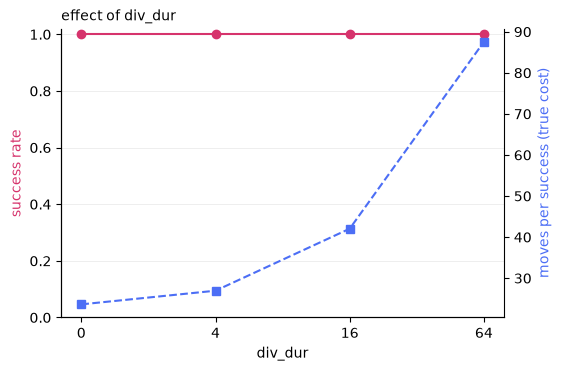

In [16]:
sweep = ss.sweep(g, 30, 340, "div_dur", [0, 4, 16, 64], experiments=40, max_moves=1500, div_freq=300)
viz.plot_sweep(sweep, parameter="div_dur");

Aspiration is worth comparing the same way. On the hard 346-edge target from earlier it raises the number of
successes a little; on many targets it makes little difference.

In [17]:
for aspiration in (False, True):
    res = ss.search(g, 30, 346, aspiration=aspiration, **settings)
    print(f"aspiration={aspiration}: {res.successes}/60 successes, {res.true_cost:.0f} moves per success")

aspiration=False: 41/60 successes, 1516 moves per success
aspiration=True: 43/60 successes, 1224 moves per success


`kick_size` often matters more. A *region kick* replaces the random moves at the start of each diversification
cycle after the first: it swaps out the $k$ subgraph vertices nearest a random one, each for the best
replacement, and keeps them out for a while (`kick_ban` moves), so it rebuilds one part of the subgraph at a
time. Edge-count and weight searches use kicks of 4 by default, which only take effect in searches longer than
`div_freq` moves. On the same target:

In [18]:
for kick_size in (0, 4, 16):
    res = ss.search(g, 30, 346, kick_size=kick_size, **settings)
    print(f"kick_size={kick_size:<2}: {res.successes}/60 successes, {res.true_cost:.0f} moves per success")

kick_size=0 : 21/60 successes, 3883 moves per success
kick_size=4 : 41/60 successes, 1516 moves per success
kick_size=16: 60/60 successes, 376 moves per success


In every problem tried, kicks of about 4 vertices helped or did no harm: this target, the maximum diversity
benchmark above, the DIMACS clique graphs, error-correcting codes and random graphs of many sizes and densities,
which is why 4 is the default. Larger kicks often help much more, but on some problems they rebuild too much
at once and do worse than none, as the codes below show, so compare a few sizes; `kick_size=0` turns kicks off.

## Regular subgraphs

`degree=` asks for subgraphs in which every vertex has exactly that many neighbors within the subgraph. A
graph is [strongly regular](https://en.wikipedia.org/wiki/Strongly_regular_graph) with parameters $(n, k, \lambda, \mu)$ when it has $n$
vertices, is $k$-regular, every two adjacent vertices have exactly $\lambda$ common neighbors, and every two
non-adjacent vertices exactly $\mu$. The [Paley graph](https://en.wikipedia.org/wiki/Paley_graph) on 61 vertices is one; here are
4-regular subgraphs on 10 of its vertices. The conflict is the total deviation from regularity,
$\sum_{v \in S} \lvert d_S(v) - d \rvert$, which is 0 exactly when every chosen vertex has $d$
neighbors among the others.

In [19]:
q = 61
squares = {x * x % q for x in range(1, q)}
paley = ss.Graph(q, [(i, j) for i in range(q) for j in range(i + 1, q) if (j - i) % q in squares])
reg = ss.search(paley, 10, degree=4, experiments=40, max_moves=2000, div_freq=300, div_dur=8)
print("degrees within the subgraph:", set(paley.induced(reg.best.vertices).degrees().tolist()))
reg

degrees within the subgraph: {4}


target,"10 vertices, regular of degree 4"
experiments,40 × ≤2000 moves
successes,40 (100%)
relative cost,18.2 moves
true cost,18.2 moves
average conflict,0.000
rng / seed,xoshiro / 1


A $d$-regular subgraph on $k$ vertices has exactly $kd/2$ edges. With `two_phase=True` the search first finds
$k$ vertices with that many edges, then makes them regular using only swaps that keep the edge count. Those
swaps are cheaper to evaluate, so although each experiment succeeds less often on hard targets, two phases
usually find solutions faster. Compare the time per success on a harder target, 8-regular subgraphs on 20
vertices (with `fixed=`, use `degree=` alone: the two-phase edge target then counts only the non-fixed
vertices, so it rarely succeeds):

In [20]:
for two_phase in (False, True):
    start = time.perf_counter()
    res = ss.search(paley, 20, degree=8, two_phase=two_phase, experiments=100, max_moves=2000, div_freq=300, div_dur=8, seed=3)
    elapsed = time.perf_counter() - start
    print(f"two_phase={two_phase}: {res.successes}/100 successes, {1000 * elapsed / max(res.successes, 1):.1f} ms per success")

two_phase=False: 42/100 successes, 8.0 ms per success
two_phase=True: 11/100 successes, 4.7 ms per success


## Cycles and trees

Cycles are the most important special case of regular subgraphs. Every vertex of an
[induced cycle](https://en.wikipedia.org/wiki/Induced_path) has exactly two neighbors on it, so `degree=2` searches for them. An
edge-count search is no substitute: a $k$-cycle spans $k$ edges, but so do many other subgraphs, such as a
triangle with a path hanging off it. A 2-regular graph is a disjoint union of cycles, though, not always a
single one, so cycles get special support: `connected=True` adds 1 to the conflict for each component beyond
the first, so only single cycles count as successes. Below 6 vertices it changes nothing, since the smallest
union of two cycles is two triangles. Here are 12-vertex searches of a sparse random graph, the one in the
README figure:

12 vertices spanning 12 edges: 0 of 100 are 2-regular
degree=2, by cycle lengths: [((12,), 110), ((3, 9), 26), ((5, 7), 26), ((4, 8), 19)]
degree=2, connected=True: 200 of 200 experiments found a single 12-cycle


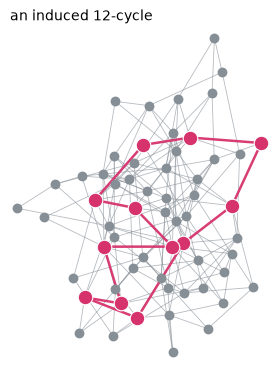

In [21]:
import collections

sparse = ss.generate("exponential", 60, 0.08, seed=3)
by_counts = ss.search(sparse, 12, 12, experiments=100, seed=1).solutions()
regular = sum(set(sparse.induced(vs).degrees().tolist()) == {2} for vs in by_counts)
print(f"12 vertices spanning 12 edges: {regular} of {len(by_counts)} are 2-regular")


def cycle_lengths(h):
    """The lengths of the cycles a 2-regular graph is made of."""
    labels, _ = h.components()
    return tuple(sorted(collections.Counter(labels).values()))


unions = ss.search(sparse, 12, degree=2, experiments=200, seed=1).solutions()
print("degree=2, by cycle lengths:", collections.Counter(cycle_lengths(sparse.induced(vs)) for vs in unions).most_common(4))
cycles = ss.search(sparse, 12, degree=2, connected=True, experiments=200, seed=1)
print(f"degree=2, connected=True: {cycles.successes} of 200 experiments found a single 12-cycle")
viz.plot_graph(sparse, cycles.best.vertices, layout=sparse.layout("spring", seed=2), title="an induced 12-cycle");   # a seed that draws it uncrossed

`connected=True` combines with the other options: `fixed=` gives cycles through chosen vertices, and raising
$k$ until successes stop finds the longest induced cycles the search can reach. Here they get rare at 28
vertices and none are found at 30. As with near misses, the longest one found is a lower bound, not a proof
that none is longer. Leave out `two_phase=True` for connected searches: its second phase makes no random
moves, so it gets stuck on unions of cycles more often.

In [22]:
def induced_cycles(k, **kwargs):
    """The distinct induced k-cycles of the sparse graph that the search finds."""
    return ss.search(sparse, k, degree=2, connected=True, experiments=200, seed=1, **kwargs).solutions()


print("10-cycles through vertex 0:", len(induced_cycles(10, fixed=[0])))
print("distinct k-cycles found, by k:", {k: len(induced_cycles(k)) for k in (24, 26, 28, 30)})

10-cycles through vertex 0: 198
distinct k-cycles found, by k: {24: 131, 26: 56, 28: 1, 30: 0}


`viz.show` displays a search's solutions on an interactive page: pick one from the menu to highlight it, drag
to pan, scroll to zoom, hover over a vertex for details and click it to pin it. Here the menu steps through
distinct induced 20-cycles. `viz.save_html` writes the same page to a file, and on the command line,
`python -m subgraphsearch explore graph.g6 --result result.json` makes one from a saved result.

In [23]:
viz.show(ss.search(sparse, 20, degree=2, connected=True, seed=1))

`connected=True` works with edge-count searches too, and there it finds induced
[trees](https://en.wikipedia.org/wiki/Tree_(graph_theory)): a connected graph on $k$ vertices with $k - 1$ edges is a tree. The edge count
alone is not enough, since $k - 1$ edges can also form a forest that contains a cycle, as `is_tree()` on the
induced subgraph shows. Raising $k$ as for cycles finds large induced trees, a classic hard problem; in this
graph they grow larger than its induced cycles.

In [24]:
for k in (10, 20):
    plain = ss.search(sparse, k, k - 1, experiments=200, seed=1)
    trees = sum(sparse.induced(e.vertices).is_tree() for e in plain.experiments if e.success)
    print(f"{k} vertices spanning {k - 1} edges: {trees} of 200 experiments ended on a tree")
induced_trees = {k: ss.search(sparse, k, k - 1, connected=True, experiments=200, seed=1).successes for k in (10, 20, 30, 35, 40)}
print("with connected=True, experiments that found a k-vertex tree, by k:", induced_trees)

10 vertices spanning 9 edges: 25 of 200 experiments ended on a tree
20 vertices spanning 19 edges: 1 of 200 experiments ended on a tree
with connected=True, experiments that found a k-vertex tree, by k: {10: 200, 20: 65, 30: 6, 35: 1, 40: 0}


## Induced paths

The shortest path between two vertices is always an induced path, and breadth-first search finds it at once.
Long induced paths are another matter: finding the longest is NP-hard, and exact searches, which must rule
out every alternative, give out on graphs of modest size. In the hypercubes below, the longest induced path
is known exactly only up to dimension 8. A heuristic search that finds long paths quickly, and reports how
close it came when it does not, fills that gap.

A path is a tree whose vertices all have degree at most 2, but beyond a few vertices the tree search rarely
ends on one. `path=True` searches for induced [paths](https://en.wikipedia.org/wiki/Path_graph) directly. It makes the regular search's
moves for degree 2, but aims at a deviation from regularity of 2 instead of 0, for the path's two endpoints
of degree 1, and at $k - 1$ edges, so it is drawn to paths rather than cycles; its conflict is 0 exactly for
an induced path. In this graph it finds paths of 29 vertices, longer than its longest induced cycle:

In [25]:
trees = ss.search(sparse, 12, 11, connected=True, experiments=200, seed=1).solutions()
print("12-vertex trees that are paths:", sum(sparse.induced(vs).is_path() for vs in trees), "of", len(trees))
paths = {k: ss.search(sparse, k, path=True, experiments=200, seed=1).successes for k in (12, 20, 25, 29, 31)}
print("path=True, experiments that found a k-vertex path, by k:", paths)

12-vertex trees that are paths: 2 of 199
path=True, experiments that found a k-vertex path, by k: {12: 200, 20: 200, 25: 197, 29: 124, 31: 0}


Trying sizes by hand, as above, is how to find the longest path the search can reach, and `ss.largest` does it
for you. Given a shape, `"path"`, `"cycle"`, `"tree"`, `"clique"` or `"independent"`, it doubles the size while
searches succeed, then bisects between the last success and the first failure, and keeps every search it made:
`.size` is the largest size found, `.best` the search at that size, and `.next` the closest failure above it,
with its near misses. Here it finds a path of 30 vertices, a size the loop above skipped.

In [26]:
longest = ss.largest(sparse, "path", experiments=200, seed=1)
print(longest.summary())
print("largest cycle and tree:", ss.largest(sparse, "cycle", experiments=200, seed=1).size,
      ss.largest(sparse, "tree", experiments=200, seed=1).size)

largest induced path found: 30 vertices, in 65 of 200 experiments
sizes tried (successes): 2 (200/200), 3 (200/200), 5 (200/200), 9 (200/200), 17 (200/200), 25 (197/200), 29 (124/200), 30 (65/200), 31 (0/200), 32 (0/200), 33 (0/200), 34 (0/200), 35 (0/200)
closest above: 31 vertices, best conflict 1


largest cycle and tree: 28 38


In the $n$-dimensional [hypercube](https://en.wikipedia.org/wiki/Hypercube_graph), whose vertices are the $n$-bit strings and whose edges
join strings that differ in one bit, the longest induced paths are the [snake-in-the-box](https://en.wikipedia.org/wiki/Snake-in-the-box)
problem, and the longest induced cycles the coil-in-the-box problem. Their known records make a good test:
the longest snake in the 7-cube has 51 vertices, and the path search finds one in under a second. In the
9-cube, the lowest dimension where the longest snake is unknown, the same search finds snakes of 185 vertices
in under three minutes, 7 short of the record of 192 vertices (191 edges), reported in 2026. Splitting the
9-cube into two 8-cubes gets closer: fixing a 95-vertex 8-cube snake in one half with `fixed=` leaves the
search only the rest to place, and it then finds snakes of 189 vertices in most experiments, 3 short of the
record, though only some 8-cube snakes work as the half. The script
[snake_9cube.py](https://github.com/vglazer/subgraphsearch/blob/main/examples/snake_9cube.py) reproduces one
in under a minute.

In [27]:
cube = ss.hypercube(7)   # vertices 0 to 127, joined when they differ in one bit
snakes = ss.search(cube, 51, path=True, experiments=400, max_moves=2000, div_freq=300, div_dur=8)
print(snakes.summary())

313/400 experiments found a 51-vertex subgraph forming a path
relative cost 752.0 moves, true cost 1307.9 moves, average conflict 0.273


The longest induced cycles, *coils*, are found with the cycle search from the previous section, `degree=2`
with `connected=True`. Their lengths are known exactly up to the 8-cube too: the longest coil in the 7-cube
has 48 vertices, which the search finds in under a second, and the longest in the 8-cube has 96, which it
finds in 4 of 200 experiments of up to 20,000 moves, in about 10 seconds.

In [28]:
coils = ss.search(cube, 48, degree=2, connected=True, experiments=400, max_moves=2000, div_freq=300, div_dur=8)
print(coils.summary())

297/400 experiments found a 48-vertex subgraph forming a cycle
relative cost 791.3 moves, true cost 1484.9 moves, average conflict 0.300


`endpoints=(s, t)` asks for induced paths that run from $s$ to $t$. The search attaches a new vertex to each
of them, which an induced path can only contain as an end, looks for a path two vertices longer through all
four, and leaves the new vertices out of the results. Here are paths between opposite corners of the 7-cube,
0 = 0000000 and 127 = 1111111. Each step along a path flips one bit, and the two corners differ in all seven,
an odd number, so a path between them has an even number of vertices: the search finds none of 47.

In [29]:
corner_paths = {}
for k in (40, 44, 47, 48):
    corner_paths[k] = ss.search(cube, k, path=True, endpoints=(0, 127), experiments=200, max_moves=5000, div_freq=300, div_dur=8)
    print(f"{k} vertices from 0 to 127: {corner_paths[k].successes} of 200 experiments")

40 vertices from 0 to 127: 200 of 200 experiments
44 vertices from 0 to 127: 200 of 200 experiments


47 vertices from 0 to 127: 0 of 200 experiments


48 vertices from 0 to 127: 140 of 200 experiments


Near misses come back as for any search, with `solutions(max_conflict=...)`, and every one of them contains
both endpoints. With endpoints, a near miss of conflict 1 has the right number of vertices, but only some of
them lie on a path from $s$ to $t$: the rest form a separate cycle. Leaving the cycle out still gives a path
from $s$ to $t$, though, as here, it can be a good deal shorter than the one asked for.

In [30]:
for vs in corner_paths[48].solutions(max_conflict=1):
    h = cube.induced(list(vs))
    labels, pieces = h.components()
    if pieces > 1:
        sizes = sorted((int((labels == c).sum()) for c in range(pieces)), reverse=True)
        print(f"a near miss: a path of {sizes[0]} vertices from 0 to 127, and a separate cycle of {sizes[1]}")
        break

a near miss: a path of 36 vertices from 0 to 127, and a separate cycle of 12


## Cliques and independent sets

A clique is a target like any other: an 11-vertex clique has all 11 · 10 / 2 = 55 edges, so this asks for 11
vertices spanning 55 edges.

40 of 40 experiments found an 11-clique; 25 distinct 11-cliques


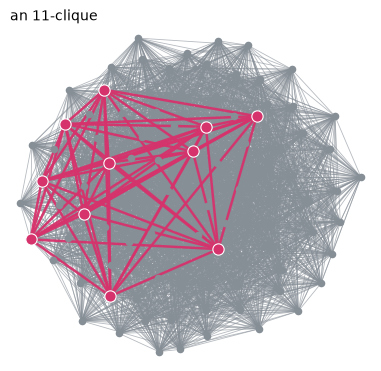

In [31]:
cliques = ss.search(g, size=11, edges=55)
print(cliques.successes, "of 40 experiments found an 11-clique;", len(cliques.solutions()), "distinct 11-cliques")
viz.plot_graph(g, cliques.best.vertices, title="an 11-clique");

An [independent set](https://en.wikipedia.org/wiki/Independent_set_(graph_theory)) is the opposite: vertices with no edges among them,
so the target is 0. It is also a clique of the complement, `g.complement()`, and the two searches find the
same sets. This graph is dense, so its independent sets are smaller than its cliques: the search finds 7
vertices every time and 8 never. `is_independent()` checks a set (and `is_clique()` a clique), on the subgraph
it induces.

In [32]:
independent = ss.search(g, 7, 0)
print(independent.successes, "of 40 experiments found a 7-vertex independent set")
print("the same as 7-cliques of the complement:", independent.solutions() == ss.search(g.complement(), 7, 21).solutions())
print("each induces no edges:", all(g.induced(vs).is_independent() for vs in independent.solutions()))

40 of 40 experiments found a 7-vertex independent set
the same as 7-cliques of the complement: True
each induces no edges: True


### Fixed vertices and neighborhoods

`fixed=` names vertices the subgraph must contain, here cliques through the vertex of highest degree. A
clique through a vertex also lies in its neighborhood, so searching the subgraph induced on the neighborhood
for one vertex fewer finds the same cliques, with a smaller graph to search.

In [33]:
v = int(g.degrees().argmax())
through_v = ss.search(g, 11, 55, fixed=[v])

nbrs = g.common_neighborhood([v])
in_nbhd = ss.search(g.induced(nbrs), 10, 45)
cliques_via_nbhd = [sorted([v, *(int(nbrs[i]) for i in vs)]) for vs in in_nbhd.solutions()]

print(f"vertex {v} has {len(nbrs)} neighbors")
print("with fixed=[v]:", through_v.successes, "of 40 experiments found an 11-clique through it")
print("in its neighborhood:", in_nbhd.successes, "of 40 found one")
assert all(g.induced_edge_count(c) == 55 for c in cliques_via_nbhd)

vertex 71 has 71 neighbors
with fixed=[v]: 29 of 40 experiments found an 11-clique through it
in its neighborhood: 38 of 40 found one


### Compared with clique solvers

Maximum cliques have methods made for them, and a standard benchmark, the DIMACS graphs, with known clique
numbers and published results. Eight of them, of three kinds, are in `examples/data` (under their own license, Creative Commons Attribution-ShareAlike,
from the Network Repository): random dense graphs (C125.9, C250.9, p_hat300-3), structured ones from geometry
and coding theory (MANN_a27, hamming8-4, keller4), and two *brock* graphs, which hide their largest clique
among many large cliques that are not quite as large, to defeat local search. The cell reads them from a
clone of the repository or else downloads them from GitHub.

Below, subgraphsearch aims at each graph's clique number with 32 experiments. It is set beside two other methods:
igraph's exact clique number, which also proves the answer (measured separately and stopped after 90
seconds), and DLS-MC, a local search made for maximum cliques, from its published results (W. Pullan and
H. H. Hoos, *Journal of Artificial Intelligence Research* 25, 2006, Table 1: mean time per run over 100 runs).
Those come from one core of a 2006 processor several times slower than today's, while subgraphsearch here uses
every core, so the comparison flatters subgraphsearch.

In [34]:
local = Path("examples/data/dimacs.g6")
url = "https://raw.githubusercontent.com/vglazer/subgraphsearch/main/examples/data/dimacs.g6"
try:
    text = local.read_text(encoding="utf-8") if local.exists() else urllib.request.urlopen(url, timeout=30).read().decode()
    dimacs = ss.parse_all(text, "graph6")
except OSError as error:
    dimacs = []
    print("could not read the benchmark graphs, so this comparison is skipped:", error)

names = ["C125.9", "C250.9", "p_hat300-3", "MANN_a27", "hamming8-4", "keller4", "brock200_2", "brock400_2"]
clique_number = [34, 44, 36, 126, 16, 11, 12, 29]
dls_mc_ms = [0.1, 0.9, 0.7, 47.6, None, None, 24.2, 477.4]   # published; None: under 0.1 ms
igraph_ms = [None, None, None, None, 18100, 1800, 300, None]   # None: not finished in 90 s

search_ms, found, successes = [], [], []
for bench, k in zip(dimacs, clique_number):   # not g: later sections use g
    start = time.perf_counter()
    res = ss.search(bench, k, k * (k - 1) // 2, experiments=32, max_moves=20000, div_freq=300, div_dur=8)
    search_ms.append(1000 * (time.perf_counter() - start))
    successes.append(res.successes)
    found.append(k if res.successes else ss.largest(bench, "clique", start=k - 8, lookahead=1, experiments=32,
                                                     max_moves=20000, div_freq=300, div_dur=8).size)

if dimacs:
    lines = ["| Graph | Vertices | Edges | Largest clique | subgraphsearch: found / 32 | DLS-MC | igraph (exact) |",
             "| --- | --- | --- | --- | --- | --- | --- |"]
    for bench, name, k, ms, f, hits, dls, ig in zip(dimacs, names, clique_number, search_ms, found, successes,
                                                     dls_mc_ms, igraph_ms):
        mine = f"{hits}/32 in {ms:.1f} ms" if f == k else f"0/32 (best {f}), {ms:.0f} ms"
        theirs = "under 0.1 ms" if dls is None else f"{dls:.1f} ms"
        exact = "over 90 s" if ig is None else f"{ig / 1000:.1f} s"
        lines.append(f"| {name} | {bench.n} | {bench.m:,} | {k} | {mine} | {theirs} | {exact} |")
    display(Markdown("\n".join(lines)))

| Graph | Vertices | Edges | Largest clique | subgraphsearch: found / 32 | DLS-MC | igraph (exact) |
| --- | --- | --- | --- | --- | --- | --- |
| C125.9 | 125 | 6,963 | 34 | 32/32 in 3.5 ms | 0.1 ms | over 90 s |
| C250.9 | 250 | 27,984 | 44 | 32/32 in 64.4 ms | 0.9 ms | over 90 s |
| p_hat300-3 | 300 | 33,390 | 36 | 32/32 in 37.1 ms | 0.7 ms | over 90 s |
| MANN_a27 | 378 | 70,551 | 126 | 5/32 in 185.1 ms | 47.6 ms | over 90 s |
| hamming8-4 | 256 | 20,864 | 16 | 32/32 in 2.4 ms | under 0.1 ms | 18.1 s |
| keller4 | 171 | 9,435 | 11 | 32/32 in 1.0 ms | under 0.1 ms | 1.8 s |
| brock200_2 | 200 | 9,876 | 12 | 0/32 (best 11), 133 ms | 24.2 ms | 0.3 s |
| brock400_2 | 400 | 59,786 | 29 | 0/32 (best 25), 407 ms | 477.4 ms | over 90 s |

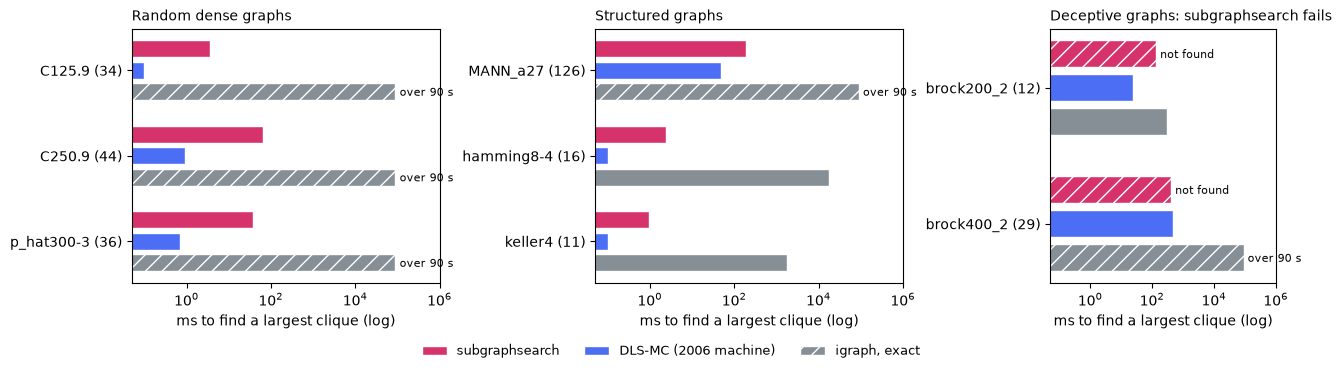

In [35]:
if dimacs:
    groups = [("Random dense graphs", [0, 1, 2]), ("Structured graphs", [3, 4, 5]),
              ("Deceptive graphs: subgraphsearch fails", [6, 7])]
    methods = [("subgraphsearch", "#d6336c"), ("DLS-MC (2006 machine)", "#4c6ef5"), ("igraph, exact", "#868e96")]
    fig, axs = plt.subplots(1, 3, figsize=(13, 3.6), layout="constrained", sharex=True,
                            gridspec_kw={"width_ratios": [3, 3, 2.2]})
    for ax, (title, rows) in zip(axs, groups):
        for y, i in enumerate(rows):
            times = [search_ms[i], dls_mc_ms[i] or 0.1, igraph_ms[i] or 90000]   # under 0.1 ms drawn at 0.1
            capped = [found[i] != clique_number[i], False, igraph_ms[i] is None]
            for j, ((label, color), t, cap) in enumerate(zip(methods, times, capped)):
                ax.barh(4 * y + j, t, color=color, hatch="//" if cap else None, edgecolor="white",
                        label=label if (y, title) == (0, groups[0][0]) else None)
                note = ("not found" if j == 0 else "over 90 s") if cap else ""
                if note:
                    ax.annotate(note, (t, 4 * y + j), xytext=(3, -3), textcoords="offset points", fontsize=8)
        ax.set_yticks([4 * y + 1 for y in range(len(rows))], [f"{names[i]} ({clique_number[i]})" for i in rows])
        ax.invert_yaxis()
        ax.set_xscale("log")
        ax.set_xlim(0.05, 1e6)
        ax.set_title(title, fontsize=10, loc="left")
        ax.set_xlabel("ms to find a largest clique (log)")
    fig.legend(loc="outside lower center", ncol=3, frameon=False, fontsize=9)

On most of these graphs subgraphsearch finds a largest clique in milliseconds, where igraph's general exact
search takes seconds or more than a minute and a half (dedicated exact clique solvers are not compared here).
DLS-MC is faster than subgraphsearch by one to two orders of magnitude on the plot, and more on equal hardware, and
it solves the brock graphs, where subgraphsearch ends in one of the decoy cliques however it is tuned. For maximum
cliques, a solver made for them is the better tool; what subgraphsearch offers is one method for many kinds of
target, most of which have no such solver.

## Switching

[Seidel switching](https://en.wikipedia.org/wiki/Two-graph#Switching_and_graphs) with respect to a vertex set $S$ swaps edges and
non-edges between $S$ and the rest of the graph. Switching a strongly regular graph with respect to a
suitable regular subgraph can give a different strongly regular graph with the same parameters. The 4×4
[rook's graph](https://en.wikipedia.org/wiki/Rook%27s_graph), the [Cartesian product](https://en.wikipedia.org/wiki/Cartesian_product_of_graphs) of two complete
graphs on 4 vertices, with parameters $(16, 6, 2, 2)$, switched with respect to an induced
8-cycle gives the [Shrikhande graph](https://en.wikipedia.org/wiki/Shrikhande_graph), the only other graph with those parameters. Here
the difference between a cycle and a union of cycles matters: switching with respect to two 4-cycles, also a
2-regular subgraph on 8 vertices, gives the rook's graph back, so the search asks for a connected one.

In [36]:
import networkx as nx

from subgraphsearch import convert


def srg_parameters(h):
    """(n, k, λ, μ) if h is strongly regular, else None."""
    A = h.adjacency_matrix().astype(int)
    common, n = A @ A, len(A)
    degrees = set(A.sum(axis=1).tolist())
    lam = {int(common[i, j]) for i in range(n) for j in range(i + 1, n) if A[i, j]}
    mu = {int(common[i, j]) for i in range(n) for j in range(i + 1, n) if not A[i, j]}
    return (n, *degrees, *lam, *mu) if len(degrees) == len(lam) == len(mu) == 1 else None


k4 = ss.Graph(4).complement()       # the complete graph on 4 vertices
rook = k4.cartesian(k4)              # squares of a 4 x 4 board, joined when in the same row or column
eight_cycle = ss.search(rook, 8, degree=2, connected=True).best.vertices
switched = rook.switch(eight_cycle)
print("rook's graph:", srg_parameters(rook), "| switched:", srg_parameters(switched))
print("isomorphic:", nx.is_isomorphic(convert.to_networkx(rook), convert.to_networkx(switched)))

rook's graph: (16, 6, 2, 2) | switched: (16, 6, 2, 2)
isomorphic: False


## Block designs

An [incidence structure](https://en.wikipedia.org/wiki/Incidence_structure) is a set of points with a family of subsets called
*blocks*. In a [block design](https://en.wikipedia.org/wiki/Block_design) with parameters $(v, k, \lambda)$ there are $v$ points,
every block has $k$ of them, and every two points lie together in exactly $\lambda$ blocks. Two graphs
come from any incidence structure: the *point graph* joins two points that lie together in some number of
blocks (`ss.Graph.point_graph`), and the *block graph* joins two blocks that share some number of points
(`ss.Graph.block_graph`), one by default in both cases.

The [Fano plane](https://en.wikipedia.org/wiki/Fano_plane) is the smallest projective plane, a $(7, 3, 1)$ design: 7 points and 7 lines
of 3 points each. In the usual picture the points are a triangle's corners, the midpoints of its sides and its
center; six lines are straight, and the seventh is the circle through the midpoints.

((0, 1, 3), (1, 2, 4), (0, 2, 5), (0, 4, 6), (1, 5, 6), (2, 3, 6), (3, 4, 5))


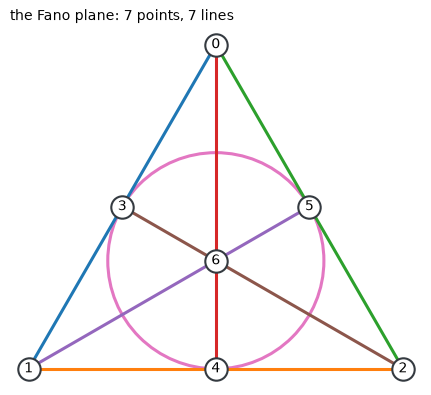

In [37]:
fano = ss.designs.FANO_PLANE   # the 7 lines, labeled as in the picture
print(fano)
viz.plot_fano_plane();

Every two points lie on exactly one line and every two lines meet in exactly one point, so both of its graphs
are complete:

In [38]:
print("point graph:", ss.Graph.point_graph(fano), "| block graph:", ss.Graph.block_graph(fano))

point graph: Graph(vertices=7, edges=21, density=1.0000) | block graph: Graph(vertices=7, edges=21, density=1.0000)


### From a design to strongly regular graphs

Designs, regular subgraph searches and switching combine into a way to construct
[strongly regular graphs](https://en.wikipedia.org/wiki/Strongly_regular_graph):

1. **Build a graph from a design** with `ss.Graph.block_graph` or `ss.Graph.point_graph`, and check that it is
   strongly regular.
2. **Search it for regular subgraphs** with `ss.search(g, k, degree=d)`, or for independent sets with
   `ss.search(g, k, 0)`.
3. **Switch** with respect to each subgraph found (`g.switch(vertices)`), and keep the switched graphs that are
   still strongly regular but not isomorphic to the original or to each other.

As an example, take every pair of 8 points as a block. Its block graph joins two pairs that share a point: the
[triangular graph](https://en.wikipedia.org/wiki/Triangular_graph) $T(8)$, strongly regular with parameters $(28, 12, 6, 4)$. Every
triangular graph $T(n)$ is the only graph with its parameters except $T(8)$, which shares them with the three
[Chang graphs](https://en.wikipedia.org/wiki/Chang_graphs), so these steps have something to find.

In [39]:
# 1. build a graph from a design: the block graph of all pairs of 8 points
pairs = [(i, j) for i in range(8) for j in range(i + 1, 8)]
t8 = ss.Graph.block_graph(pairs)
print("T(8):", srg_parameters(t8))

T(8): (28, 12, 6, 4)


Each Chang graph is $T(8)$ switched with respect to a set of pairs: four disjoint pairs, eight pairs forming an
8-cycle on the points, or a triangle plus a 5-cycle. In $T(8)$ these are independent sets of 4 vertices and
2-regular subgraphs on 8 vertices, so the search looks for both:

In [40]:
# 2. search for regular subgraphs: independent sets of 4 vertices, and 2-regular subgraphs on 8
independent = ss.search(t8, 4, 0, experiments=20).solutions()
two_regular = ss.search(t8, 8, degree=2, experiments=200).solutions()
print(len(independent), "independent sets and", len(two_regular), "2-regular subgraphs found")

18 independent sets and 198 2-regular subgraphs found


Switching with respect to each one gives a graph to check. To tell the switched graphs apart, the cell compares
the sizes of their maximal cliques. Relabeling vertices cannot change them, so graphs whose clique sizes differ
cannot be isomorphic. This takes milliseconds, where testing isomorphism directly takes about 0.1 seconds per
pair of these graphs:

In [41]:
# 3. switch, and keep the strongly regular graphs not isomorphic to T(8) or to each other
def clique_sizes(h):
    """The sizes of all maximal cliques, sorted: isomorphic graphs have the same."""
    return sorted(len(c) for c in nx.find_cliques(convert.to_networkx(h)))


def described(vertices):
    """What the pairs at these vertices of T(8) form on the 8 points."""
    on_points = nx.Graph([pairs[v] for v in vertices])
    cycles = tuple(sorted(len(c) for c in nx.connected_components(on_points)))
    return {(2, 2, 2, 2): "4 disjoint pairs", (8,): "an 8-cycle", (3, 5): "a triangle and a 5-cycle"}.get(cycles, f"cycles {cycles}")


seen = [clique_sizes(t8)]
chang = []   # (description, switched vertices, graph), one per isomorphism class
for vertices in independent + two_regular:
    switched = t8.switch(vertices)
    if srg_parameters(switched) != (28, 12, 6, 4):
        continue
    sizes = clique_sizes(switched)
    if sizes not in seen:
        seen.append(sizes)
        chang.append((described(vertices), vertices, switched))

for how, _, h in chang:
    print(f"switching T(8) with respect to {how}: {srg_parameters(h)}, not isomorphic to T(8) or the others")

switching T(8) with respect to 4 disjoint pairs: (28, 12, 6, 4), not isomorphic to T(8) or the others
switching T(8) with respect to an 8-cycle: (28, 12, 6, 4), not isomorphic to T(8) or the others
switching T(8) with respect to a triangle and a 5-cycle: (28, 12, 6, 4), not isomorphic to T(8) or the others


The top row draws each set of pairs on the 8 points, and the bottom row the graph it gives, with the switched
vertices first on the ring. Switching leaves the edges among them alone, so they still form the same cycles.

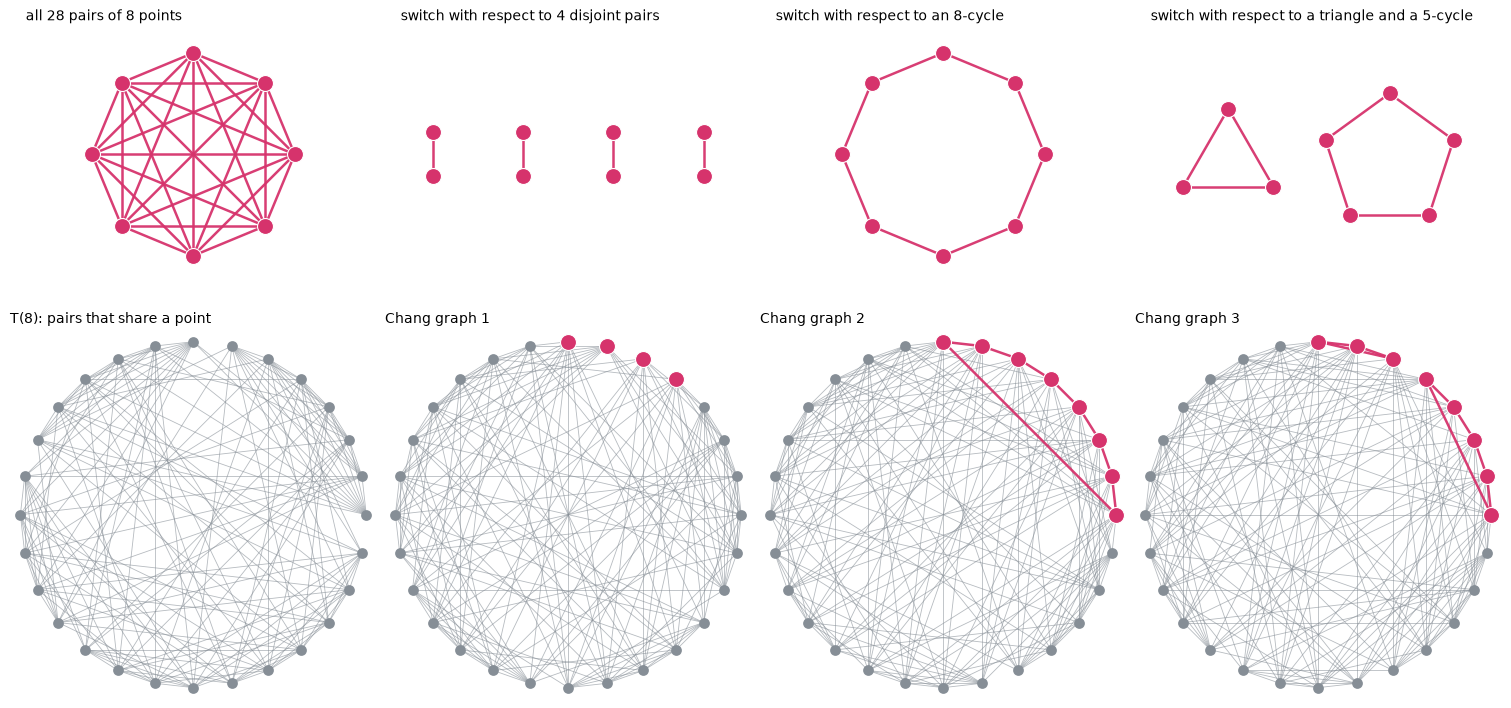

In [42]:
viz.plot_switchings(
    t8, [vertices for _, vertices, _ in chang],
    graph_title="T(8): pairs that share a point", titles=[f"Chang graph {i}" for i in range(1, len(chang) + 1)],
    above=[ss.Graph(8, pairs)] + [ss.Graph(8, [pairs[v] for v in vertices]) for _, vertices, _ in chang],
    above_titles=["all 28 pairs of 8 points"] + [f"switch with respect to {how}" for how, _, _ in chang],
);

## Spectral bounds

A graph's eigenvalues limit the subgraphs it can contain. In a $k$-regular graph on $n$ vertices whose
adjacency matrix has smallest eigenvalue $\lambda$, an independent set has at most $n(-\lambda)/(k - \lambda)$
vertices: the [Hoffman bound](https://en.wikipedia.org/wiki/Hoffman%27s_ratio_bound). In a strongly regular graph, and more generally in a
distance-regular one such as a hypercube, a clique has at most $1 - k/\lambda$ vertices: the Delsarte bound. A search can only show what a graph contains, never what it
lacks, but the bounds supply the other half: when the search finds a set as large as a bound allows, it has
found the largest there is.

Here are the largest independent sets and cliques `ss.largest` finds in a few strongly regular graphs and the
5-cube, against the two bounds. The Clebsch graph is the 4-cube with each vertex also joined to the one
opposite it.

In [43]:
import itertools

import matplotlib.pyplot as plt
import numpy as np


def paley(q):
    squares = {x * x % q for x in range(1, q)}
    return ss.Graph(q, [(u, v) for u in range(q) for v in range(u + 1, q) if (v - u) % q in squares])


def bounds(g):
    eigenvalues = np.linalg.eigvalsh(g.adjacency_matrix(dtype=float))
    k, low = eigenvalues[-1], eigenvalues[0]
    return g.n * -low / (k - low), 1 - k / low       # Hoffman (independent sets), Delsarte (cliques)


five = list(itertools.combinations(range(5), 2))
spectral = {
    "Petersen": ss.Graph(10, [(i, j) for i, j in itertools.combinations(range(10), 2) if not set(five[i]) & set(five[j])]),
    "T(8)": t8,
    "rook's 6 x 6": ss.Graph(6).complement().cartesian(ss.Graph(6).complement()),
    "5-cube": ss.hypercube(5),
    "Clebsch": ss.Graph(16, ss.hypercube(4).edge_list() + [(u, u ^ 15) for u in range(8)]),
    "Paley 61": paley(61),
    "Paley 197": paley(197),
}
largest = {}
for name, graph in spectral.items():
    hoffman, delsarte = bounds(graph)
    largest[name] = (ss.largest(graph, "independent", experiments=64, max_moves=2000),
                     ss.largest(graph, "clique", experiments=64, max_moves=2000))
    independent, clique = (r.size for r in largest[name])
    print(f"{name:13} independent set {independent:2} (Hoffman: at most {hoffman:5.2f})   clique {clique:2} (Delsarte: at most {delsarte:5.2f})")

Petersen      independent set  4 (Hoffman: at most  4.00)   clique  2 (Delsarte: at most  2.50)
T(8)          independent set  4 (Hoffman: at most  4.00)   clique  7 (Delsarte: at most  7.00)
rook's 6 x 6  independent set  6 (Hoffman: at most  6.00)   clique  6 (Delsarte: at most  6.00)
5-cube        independent set 16 (Hoffman: at most 16.00)   clique  2 (Delsarte: at most  2.00)
Clebsch       independent set  5 (Hoffman: at most  6.00)   clique  2 (Delsarte: at most  2.67)


Paley 61      independent set  5 (Hoffman: at most  7.81)   clique  5 (Delsarte: at most  7.81)
Paley 197     independent set  8 (Hoffman: at most 14.04)   clique  8 (Delsarte: at most 14.04)


In the first four graphs every set found is as large as its bound allows, rounded down to a whole number, so it
is as large as possible, and the sets are familiar ones. In the Petersen graph, whose vertices are the pairs
from 5 points joined when disjoint, the 4 pairs through a point, and 2 disjoint pairs, since 5 points have no
3 disjoint pairs. In $T(8)$, whose vertices are the pairs from 8 points joined when they meet, 4 disjoint
pairs and the 7 pairs through a point. In the rook's graph, 6 squares no two in a row or column, the pattern
of a permutation, and a whole row or column. In the 5-cube, the 16 words of even weight.

Meeting the Hoffman bound has a consequence one can check: every vertex outside such an independent set $S$
has exactly $k\lvert S \rvert / (n - \lvert S \rvert)$ neighbors in it, the same number for all. The Clebsch graph's
independent sets fall one short of its bound, and there the counts differ. The Paley graphs, the standard
"random-looking" strongly regular graphs, fall far short of both bounds; how large their cliques really are is
a well-known open problem.

In [44]:
def neighbors_inside(g, vertices):
    inside = set(vertices)
    return sorted({sum(int(w) in inside for w in g.neighbors(v)) for v in range(g.n) if v not in inside})


for name in ("Petersen", "T(8)", "rook's 6 x 6", "5-cube", "Clebsch"):
    print(f"{name:13} vertices outside the independent set have", neighbors_inside(spectral[name], largest[name][0].best.best.vertices),
          "neighbors in it")

Petersen      vertices outside the independent set have [2] neighbors in it
T(8)          vertices outside the independent set have [2] neighbors in it
rook's 6 x 6  vertices outside the independent set have [2] neighbors in it
5-cube        vertices outside the independent set have [5] neighbors in it
Clebsch       vertices outside the independent set have [2, 5] neighbors in it


## Edges and eigenvalues

The bounds above are the extreme cases of a statement about every vertex set. In a $d$-regular graph on $n$
vertices with adjacency eigenvalues $d = \theta_1 \ge \theta_2 \ge \dots \ge \theta_n$, a set $S$ of $k$ vertices spans
$e(S)$ edges with

$$\frac{d k^2}{2n} + \theta_n \frac{k (n - k)}{2n} \;\le\; e(S) \;\le\; \frac{d k^2}{2n} + \theta_2 \frac{k (n - k)}{2n}.$$

The first term is what a random set of $k$ vertices spans on average. The upper bound limits how few edges can
leave a set, since each of its vertices has $d$ edges in all: at least $(d - \theta_2)\,k(n - k)/n$ of them, the
easy half of [Cheeger's inequality](https://en.wikipedia.org/wiki/Cheeger_constant_(graph_theory)) on the graph's
[expansion](https://en.wikipedia.org/wiki/Expander_graph). At $e(S) = 0$ the lower bound is the Hoffman bound. Bounding the deviation from
random on both sides at once, by the larger of $\theta_2$ and $\lvert \theta_n \rvert$, is the
[expander mixing lemma](https://en.wikipedia.org/wiki/Expander_mixing_lemma).

Finding the most or fewest edges $k$ vertices can span is exactly what the search does: ask for $k$ vertices
with $m$ edges, starting at a bound and moving inward until a search succeeds (not every count in between is
possible). Below, for each $k$, the deviation from random is divided by $k(n - k)/(2n)$, so the two bounds become
horizontal lines at $\theta_2$ and $\theta_n$, and the points are the extremes the search finds.

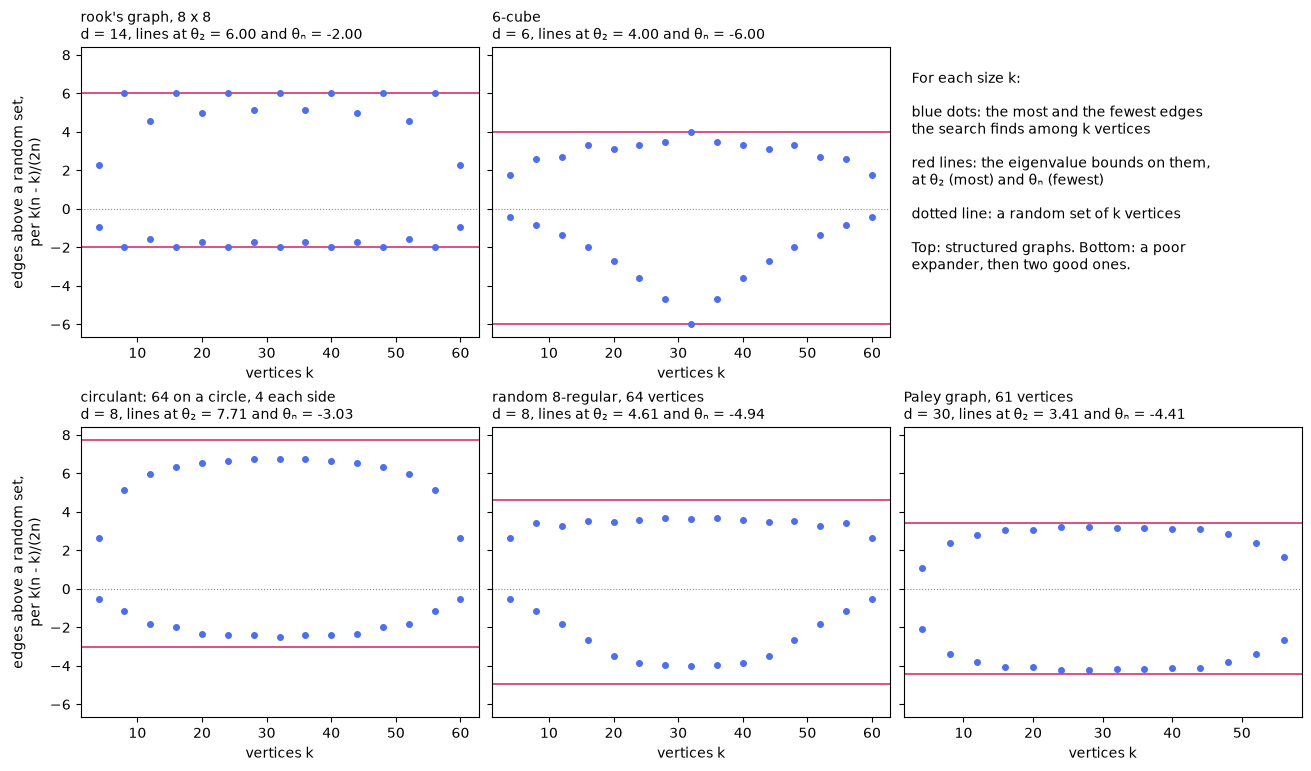

In [45]:
def extreme_edges(graph, k, start, step):
    # the first edge count the search finds, starting at a bound and moving inward
    m = start
    while ss.search(graph, k, m, experiments=32, max_moves=2000).successes == 0:
        m += step
    return m


mixing = {
    "rook's graph, 8 x 8": ss.Graph(8).complement().cartesian(ss.Graph(8).complement()),
    "6-cube": ss.hypercube(6),
    "circulant: 64 on a circle, 4 each side": ss.Graph(64, [(u, (u + s) % 64) for u in range(64) for s in range(1, 5)]),
    "random 8-regular, 64 vertices": ss.random_regular(64, 8, seed=1),
    "Paley graph, 61 vertices": paley(61),
}
# two structured graphs on top, then from a poor expander to good ones below; a key in the spare corner
fig, grid = plt.subplots(2, 3, figsize=(13, 7.6), layout="constrained", sharey=True)
panels = [grid[0, 0], grid[0, 1], grid[1, 0], grid[1, 1], grid[1, 2]]
for ax, (name, graph) in zip(panels, mixing.items()):
    n = graph.n
    eigenvalues = np.linalg.eigvalsh(graph.adjacency_matrix(dtype=float))
    d, second, smallest = eigenvalues[-1], eigenvalues[-2], eigenvalues[0]
    sizes, fewest, most = range(4, n - 3, 4), [], []
    for k in sizes:
        random_set, scale = d * k * k / (2 * n), k * (n - k) / (2 * n)
        high = extreme_edges(graph, k, int(np.floor(random_set + second * scale + 1e-9)), -1)
        low = extreme_edges(graph, k, max(0, int(np.ceil(random_set + smallest * scale - 1e-9))), 1)
        most.append((high - random_set) / scale)
        fewest.append((low - random_set) / scale)
    for line in (second, smallest):
        ax.axhline(line, color="#d6336c", lw=1.2)
    ax.axhline(0, color="#868e96", lw=0.8, ls=":")
    ax.plot(sizes, most, "o", sizes, fewest, "o", color="#4c6ef5", ms=4)
    ax.set_title(f"{name}\nd = {d:.0f}, lines at θ₂ = {second:.2f} and θₙ = {smallest:.2f}", fontsize=10, loc="left")
    ax.set_xlabel("vertices k")
for ax in grid[:, 0]:
    ax.set_ylabel("edges above a random set,\nper k(n - k)/(2n)")
grid[0, 2].axis("off")
grid[0, 2].text(0.02, 0.92, "For each size k:\n\n"
                "blue dots: the most and the fewest edges\nthe search finds among k vertices\n\n"
                "red lines: the eigenvalue bounds on them,\nat θ₂ (most) and θₙ (fewest)\n\n"
                "dotted line: a random set of k vertices\n\n"
                "Top: structured graphs. Bottom: a poor\nexpander, then two good ones.",
                va="top", fontsize=10, transform=grid[0, 2].transAxes);

Where a point sits on a line, the search has found a set as uneven as the eigenvalues allow, so the bound is
sharp there. In the rook's graph that happens at every multiple of 8, on both lines: whole rows span the most
edges, and squares forming permutation patterns the fewest. In the 6-cube it happens at half the cube, 32
vertices: a 5-dimensional subcube on the upper line, the words of even weight on the lower one.

The bottom row has graphs of the same degree, or about it, and runs from a poor expander to good ones. In the
circulant, each vertex joined to its 4 nearest neighbors on either side around a circle, $\theta_2$ is almost $d$:
the upper line is near the top, and the search finds sets of every size, arcs of the circle, with almost all
their edges inside and only a few leaving. That is the other half of Cheeger's inequality at work: a small gap
between $d$ and $\theta_2$ means some set has few edges leaving it, and the search finds one. A random 8-regular
graph is the opposite. Its eigenvalues other than $d$ are about as small as they can be, within the Ramanujan
bound $2\sqrt{{d - 1}}$, so its lines are close together and every set spans nearly the number of edges a random
set would: that is what it means for a graph to be an expander. Its points even stay well inside its lines,
so here the eigenvalues understate how close to random its sets are. The Paley graph, the standard
pseudo-random graph, is an expander too, and in it the points come close to both lines.

## Vectors with prescribed inner products

Many objects in linear algebra are sets of vectors with prescribed inner products, and so are cliques in a
graph on the candidate vectors. `ss.Graph.from_vectors(vectors, inner_products)` builds that graph: one vertex
per row, two joined when their inner product is one of `inner_products`. It computes the inner products in
parallel straight into the adjacency matrix, so even graphs with hundreds of millions of edges take seconds.

A [Hadamard matrix](https://en.wikipedia.org/wiki/Hadamard_matrix) of order $n$ is an $n \times n$ matrix of $\pm 1$ entries with pairwise
orthogonal rows, $H H^T = n I$. Negating columns and then rows makes its first row and column all $+1$, and
then its other $n - 1$ rows are $\pm 1$ vectors that start with $+1$, sum to 0 (being orthogonal to the first
row) and are pairwise orthogonal. So in the graph on all such vectors, joined when orthogonal, a Hadamard
matrix of order $n$ is a clique on $n - 1$ vertices. For order 12 the graph has 462 vertices, and the search
finds a clique at once; `examples/hadamard.py` also does orders 8, 16 and 20. Choosing orthogonal rows one at a
time, at random, also works at orders 12 and 16, but at order 20 it gets stuck after 10 of the 18 rows about a
third of the time, while the search finds all 18 every time.

In [46]:
n = 12
# +1 followed by the 11-entry +-1 vectors with six -1s: all candidates for the rows after the first
rest = ss.vectors.signs(ss.vectors.binary_words(n - 1, weight=n // 2))
rows = np.hstack([np.ones((len(rest), 1), dtype=int), rest])
orthogonal = ss.Graph.from_vectors(rows, [0])

found = ss.search(orthogonal, n - 1, (n - 1) * (n - 2) // 2, experiments=16, max_moves=1000)
h = np.vstack([np.ones(n, dtype=int), rows[list(found.best.vertices)]])
print(f"{orthogonal.n} vectors; {found.successes} of 16 experiments found a clique of {n - 1}")
print("a Hadamard matrix:", ss.vectors.is_hadamard(h))

462 vectors; 16 of 16 experiments found a clique of 11
a Hadamard matrix: True


The matrix the search found looks random, on the left below ($+1$ dark, $-1$ white). But reordering the rows
and columns of a Hadamard matrix, or negating some of them, gives another one, and up to those changes there
is only one Hadamard matrix of order 12: [Paley's](https://en.wikipedia.org/wiki/Paley_construction), built from the squares modulo 11.
Below its first row, Paley's matrix is $I + Q$ next to a column of $-1$s, where $Q_{ij}$ is $+1$ when $j - i$
is a nonzero square mod 11, $-1$ when it is not a square, and 0 when $j = i$. $Q$ depends only on $j - i$, so
each row is the one above shifted by one place: the diagonal stripes on the right.

Finding the reordering and the signs that turn the search's matrix into Paley's is a graph isomorphism
problem. Give each row and each column two vertices, one for each sign, join a row vertex to a column vertex
when the entry with those signs is $+1$, and join each row's or column's two vertices to each other. Then two
matrices are equivalent exactly when their graphs are isomorphic, and an isomorphism maps each row and column,
with its sign, to its place in the other matrix.

Paley's matrix is a Hadamard matrix: True
reordered and negated, the search's matrix is Paley's: True


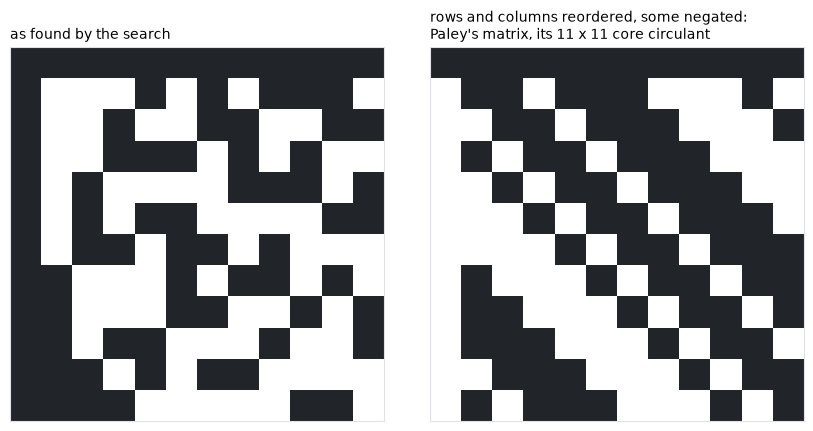

In [47]:
# Paley's matrix of order 12, from the squares mod 11
squares = {x * x % 11 for x in range(1, 11)}
Q = np.array([[0 if i == j else 1 if (j - i) % 11 in squares else -1 for j in range(11)] for i in range(11)])
paley = np.eye(n, dtype=int)
paley[0, 1:] = 1
paley[1:, 0] = -1
paley[1:, 1:] += Q
print("Paley's matrix is a Hadamard matrix:", ss.vectors.is_hadamard(paley))


def signed(m):
    # two vertices per row and per column, one for each sign
    g = nx.Graph()
    for i in range(n):
        g.add_edge(("row", i, 1), ("row", i, -1), kind="pair")
        g.add_edge(("col", i, 1), ("col", i, -1), kind="pair")
    for i, j in itertools.product(range(n), repeat=2):
        for a, b in itertools.product((1, -1), repeat=2):
            if a * b * m[i, j] == 1:
                g.add_edge(("row", i, a), ("col", j, b))
    nx.set_node_attributes(g, {v: v[0] for v in g}, "side")
    return g


same_side = lambda x, y: x["side"] == y["side"]   # rows go to rows, columns to columns
match = next(nx.algorithms.isomorphism.GraphMatcher(signed(h), signed(paley), node_match=same_side).isomorphisms_iter())
rows_to, cols_to = np.zeros((n, n), dtype=int), np.zeros((n, n), dtype=int)
for i in range(n):
    _, k, sign = match[("row", i, 1)]
    rows_to[k, i] = sign           # row i of h becomes row k, times sign
    _, k, sign = match[("col", i, 1)]
    cols_to[i, k] = sign           # column i of h becomes column k, times sign
print("reordered and negated, the search's matrix is Paley's:", (rows_to @ h @ cols_to == paley).all())

fig, axs = plt.subplots(1, 2, figsize=(8.4, 4.2), layout="constrained")
viz.plot_sign_matrix(h, axs[0], title="as found by the search")
viz.plot_sign_matrix(rows_to @ h @ cols_to, axs[1], title="rows and columns reordered, some negated:\nPaley's matrix, its 11 x 11 core circulant");

[Equiangular lines](https://en.wikipedia.org/wiki/Equiangular_lines) are lines through the origin with the same angle between every pair.
Lines given by vectors of equal length are equiangular when all their inner products are $\pm c$, so they too
are cliques. Taking one $\pm 1$ vector of length 6 per line (the 32 that start with $+1$) and asking for inner
products $\pm 2$, that is $\lvert \cos \rvert = 1/3$, `ss.largest` finds 16 lines spanning all 6 dimensions:
the most equiangular lines there can be in $\mathbb{R}^6$.

Their *Seidel matrix* $S$ holds the signs of the inner products, with 0 on the diagonal, so the Gram matrix of
the unit vectors is $I + S/3$. That matrix is positive semidefinite of rank 6, which means $S$ has smallest
eigenvalue $-3$ with multiplicity $16 - 6 = 10$, as printed below. In general, $n$ lines at
$\lvert \cos \rvert = a$ span $n - m$ dimensions, where $m$ is the multiplicity of the eigenvalue $-1/a$.

In [48]:
d = 6
signs = ss.vectors.signs(ss.vectors.binary_words(d - 1))
lines = np.hstack([np.ones((len(signs), 1), dtype=int), signs])   # the 32 +-1 vectors starting with +1
equiangular = ss.largest(ss.Graph.from_vectors(lines, [-2, 2]), "clique", experiments=64, max_moves=3000)
chosen = lines[list(equiangular.best.best.vertices)]
gram = np.abs(chosen @ chosen.T)
print(equiangular.size, "lines spanning", np.linalg.matrix_rank(chosen), "dimensions")
print("every pair at |cos| = 2/6:", (gram[np.triu_indices(len(chosen), 1)] == 2).all())
seidel = np.sign(chosen @ chosen.T) - np.eye(len(chosen), dtype=int)
values, counts = np.unique(np.round(np.linalg.eigvalsh(seidel)).astype(int), return_counts=True)
print("Seidel eigenvalues:", ", ".join(f"{v} ({c} times)" for v, c in zip(values, counts)))

16 lines spanning 6 dimensions
every pair at |cos| = 2/6: True
Seidel eigenvalues: -3 (10 times), 5 (6 times)


A line has two direction vectors, $v$ and $-v$, and choosing the other one negates its row and column of $S$:
that is Seidel switching, from the switching section above, and it does not change the lines. Choosing
directions so that line 0 makes an acute angle with every other line turns the first row and column of $S$ all
dark ($+1$), on the left below. The other 15 lines then have a structure of their own: joined when they make an
acute angle, they form the line graph of $K_6$, a strongly regular graph. So each of them can be labeled by
one of the 15 edges of $K_6$, as on the right, and two of the lines make an acute angle exactly when their edges
share an endpoint; otherwise the angle is obtuse.

acute exactly when the edges share an endpoint: True


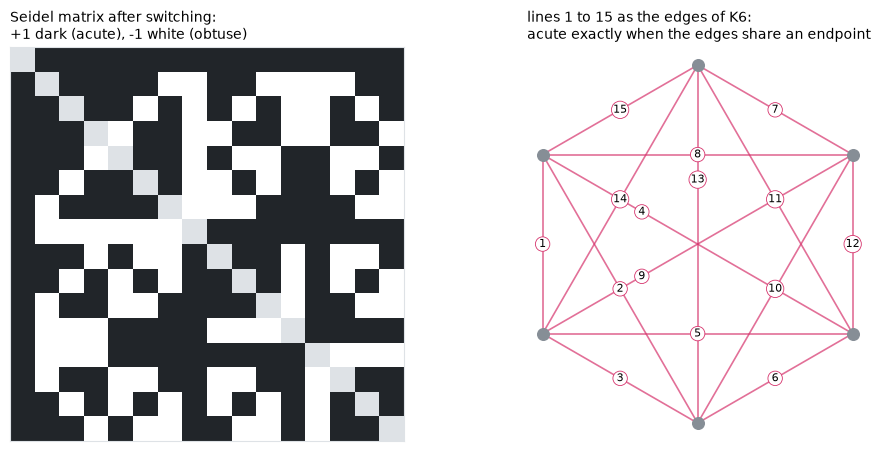

In [49]:
first = np.sign(chosen @ chosen[0])
first[0] = 1
switched = chosen * first[:, None]        # line 0 now at an acute angle to every other line
seidel = np.sign(switched @ switched.T) - np.eye(16, dtype=int)

# lines 1 to 15, joined when acute, are the line graph of K6: match each line to an edge of K6
acute = nx.Graph([(i, j) for i in range(1, 16) for j in range(i + 1, 16) if seidel[i, j] == 1])
edge_of = next(nx.algorithms.isomorphism.GraphMatcher(acute, nx.line_graph(nx.complete_graph(6))).isomorphisms_iter())
print("acute exactly when the edges share an endpoint:",
      all((seidel[i, j] == 1) == bool(set(edge_of[i]) & set(edge_of[j])) for i in range(1, 16) for j in range(i + 1, 16)))

fig, axs = plt.subplots(1, 2, figsize=(9.8, 4.4), layout="constrained")
viz.plot_sign_matrix(seidel, axs[0], title="Seidel matrix after switching:\n+1 dark (acute), -1 white (obtuse)")
corner = {p: (np.cos(np.pi / 2 + np.pi * p / 3), np.sin(np.pi / 2 + np.pi * p / 3)) for p in range(6)}
for line, (a, b) in edge_of.items():
    (x0, y0), (x1, y1) = corner[a], corner[b]
    axs[1].plot([x0, x1], [y0, y1], color="#d6336c", lw=1.2, alpha=0.7)
    t = 0.32 if abs(a - b) == 3 else 0.5   # keep the three diameters' labels apart
    axs[1].annotate(str(line), ((1 - t) * x0 + t * x1, (1 - t) * y0 + t * y1), ha="center", va="center", fontsize=8,
                    bbox={"boxstyle": "circle,pad=0.15", "fc": "white", "ec": "#d6336c", "lw": 0.6})
axs[1].scatter(*zip(*corner.values()), s=70, color="#868e96", zorder=3)
axs[1].set_aspect("equal")
axs[1].axis("off")
axs[1].set_title("lines 1 to 15 as the edges of K6:\nacute exactly when the edges share an endpoint", fontsize=10, loc="left");

## Error-correcting codes

A binary [code](https://en.wikipedia.org/wiki/Error_correction_code) of length $n$ and minimum distance $d$ is a set of $n$-bit words,
any two of which differ in at least $d$ places. Then a word sent with up to $(d - 1)/2$ bits flipped is still
closer to the word sent than to any other, so the receiver can correct those errors, and up to $d - 1$ flipped
bits are always noticed, since they cannot turn one word into another. The more words, the more messages; the
largest number of words possible, $A(n, d)$, is known only for small $n$ and $d$.

Codes are cliques too: in the graph on all $2^n$ words, joined when they differ in at least $d$ places, a code
is a clique, and $A(n, d)$ is the size of the largest. `ss.Graph.from_words(words, distances)` builds that graph.
They are also vectors with prescribed inner products: written as $\pm 1$ vectors, two words that differ in $t$
places have inner product $n - 2t$, which is how the decoding below finds the nearest word. For length 11 and distance 4 the most
words a code can have is 72, and the search finds such a code in a fraction of a second; `examples/codes.py`
finds the largest codes for lengths 9 to 12 and distances 4 and 6.

In [50]:
n, d = 11, 4
words = ss.vectors.binary_words(n)                        # all 2048 words, as rows of 0s and 1s
far_apart = ss.Graph.from_words(words, range(d, n + 1))   # joined when at distance d or more
found = ss.search(far_apart, 72, 72 * 71 // 2, experiments=16, max_moves=2000)
print(f"{found.successes} of 16 experiments found a code of 72 words")
print("minimum distance:", ss.vectors.min_distance(words[list(found.best.vertices)]))
code = ss.vectors.signs(words[list(found.best.vertices)])    # as +-1 vectors, for decoding by inner products

# send each word with bits flipped, and decode to the nearest word of the code
rng = np.random.default_rng(1)
def received(word, flips):
    out = word.copy()
    out[rng.choice(n, flips, replace=False)] *= -1
    return out
one = [received(w, 1) for w in code]
corrected = sum(np.argmax(code @ r) == i for i, r in enumerate(one))    # nearest word: largest inner product
two = [received(w, 2) for w in code]
noticed = sum(not (code @ r == n).any() for r in two)                   # not equal to any word of the code
print(f"one bit flipped: {corrected} of 72 words decoded correctly")
print(f"two bits flipped: {noticed} of 72 noticed as errors")

10 of 16 experiments found a code of 72 words
minimum distance: 4


one bit flipped: 72 of 72 words decoded correctly
two bits flipped: 72 of 72 noticed as errors


A code can be searched the other way round too: as an independent set in the graph of words that are *too
close*, joined when they differ in fewer than $d$ places. That graph is sparse, and distances in it mean
something: the codewords nearest a codeword lie in one region of the space of words. A region kick (see
Tuning) then removes the $k$ codewords nearest a random one and refills the gap with the best words it can
find, rebuilding one region of the code at a time, the kind of move searches for codes use.

How large a region to rebuild depends on the problem, so the size is a setting to compare. Here it is for the
72-word code above and for a [constant-weight code](https://en.wikipedia.org/wiki/Constant-weight_code): 69 words of length 15, each with
seven 1s, at distance at least 6 from one another, also the most there can be:

In [51]:
weight_7 = ss.vectors.binary_words(15, weight=7)
codes = {
    "72 words of length 11": (ss.Graph.from_words(words, range(1, 4)), 72),       # joined when less than 4 apart
    "69 words of weight 7": (ss.Graph.from_words(weight_7, range(1, 6)), 69),     # joined when less than 6 apart
}
print(f"{'':12}" + "".join(f"{name:>30}" for name in codes))
for kick_size in (0, 4, 32):
    row = []
    for too_close, size in codes.values():
        res = ss.search(too_close, size, 0, kick_size=kick_size, experiments=64, max_moves=5000, div_freq=300, div_dur=8)
        row.append(f"{res.successes:2}/64 found, {res.true_cost:6.0f} moves")
    print(f"kick_size={kick_size:<2}" + "".join(f"{cell:>30}" for cell in row))

                     72 words of length 11          69 words of weight 7


kick_size=0      33/64 found,   4989 moves     25/64 found,  10167 moves


kick_size=4      36/64 found,   4427 moves     31/64 found,   8012 moves


kick_size=32     63/64 found,    793 moves     10/64 found,  28849 moves


Each code wants what the other cannot stand. The 72-word code gains from rebuilding large regions: kicks of 32
codewords, nearly half the code, find it in nearly every experiment with about a sixth of the work. The constant-weight code
is best with small kicks of 4 and is wrecked by large ones. So compare a few sizes on a problem, as for any
setting, before relying on one.

## Graph structure

`viz.plot_graph_summary` shows three views of a graph: its [degree distribution](https://en.wikipedia.org/wiki/Degree_distribution) next to
that of an Erdős–Rényi graph of the same density, its Laplacian spectrum, and its adjacency matrix with a
subgraph's vertices moved to the top-left block. Here it is for the dense graph from the start, with the
30-vertex, 346-edge subgraph found earlier. This section's tools also accept a `WeightedGraph`, and use its
edges without their weights.

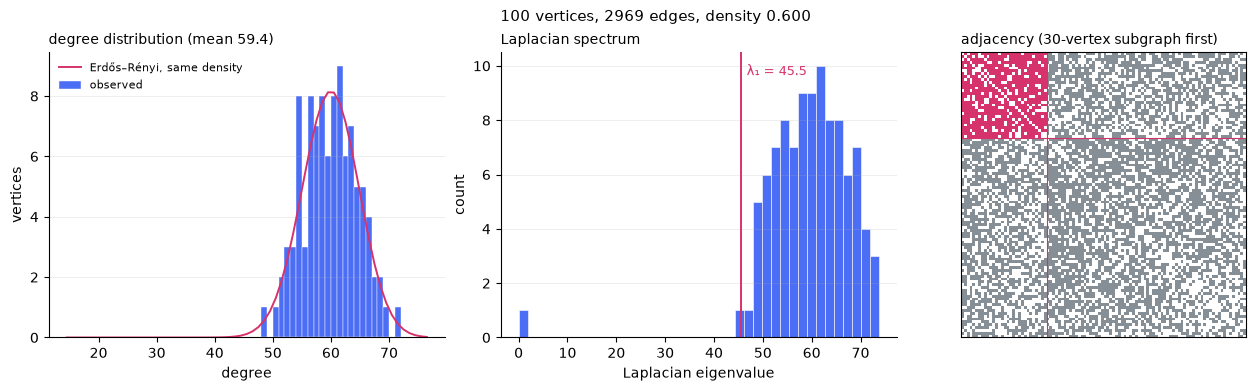

In [52]:
viz.plot_graph_summary(g, highlight=r.best.vertices);

The [Laplacian](https://en.wikipedia.org/wiki/Laplacian_matrix) of a graph is $L = D - A$, where $D$ is the diagonal matrix of degrees
and $A$ the adjacency matrix. Its eigenvalues $\lambda_0 \le \lambda_1 \le \dots$ are never negative,
$\lambda_0$ is always 0, and the number of eigenvalues equal to 0 is the number of connected components. So the
second-smallest, $\lambda_1$, called the [algebraic connectivity](https://en.wikipedia.org/wiki/Algebraic_connectivity), is positive
exactly when the graph is connected. It also measures how well connected the graph is. *Fiedler's bound*
(1973) says that unless the graph is complete, $\lambda_1 \le \kappa$, where $\kappa$ is the
[vertex connectivity](https://en.wikipedia.org/wiki/Connectivity_(graph_theory)), the fewest vertices whose removal disconnects the graph.
So removing fewer than $\lambda_1$ vertices can never disconnect it.

The middle panel is a histogram of all 100 eigenvalues. The lone bar at 0 is $\lambda_0$, and the red line
marks $\lambda_1$, far from 0, so this graph is connected and hard to break apart. The vertex connectivity
can never exceed the smallest degree, since removing a vertex's neighbors cuts it off, so $\kappa$ lies
between $\lambda_1$ and the smallest degree. Here that means between 46 and 48, and computing it gives 48. Two separate 4-cycles, by contrast, have two zero eigenvalues and $\lambda_1 = 0$:

In [53]:
fiedler = viz.spectral_summary(g)["algebraic_connectivity"]
kappa = nx.node_connectivity(convert.to_networkx(g))
print(f"Fiedler's bound: algebraic connectivity {fiedler:.1f} <= vertex connectivity {kappa} "
      f"<= smallest degree {g.degrees().min()}")

two_cycles = ss.Graph(8, [(0, 1), (1, 2), (2, 3), (3, 0), (4, 5), (5, 6), (6, 7), (7, 4)])
for name, h in [("g", g), ("two 4-cycles", two_cycles)]:
    eigenvalues = viz.laplacian_spectrum(h)
    print(f"{name}: {sum(abs(eigenvalues) < 1e-9)} zero eigenvalue(s), algebraic connectivity "
          f"{viz.spectral_summary(h)['algebraic_connectivity']:.1f}")

Fiedler's bound: algebraic connectivity 45.5 <= vertex connectivity 48 <= smallest degree 48
g: 1 zero eigenvalue(s), algebraic connectivity 45.5
two 4-cycles: 2 zero eigenvalue(s), algebraic connectivity 0.0


Despite its name, the `"power"` model has no heavy tail, so its graphs are not
[scale-free](https://en.wikipedia.org/wiki/Scale-free_network); the comparison makes that plain:

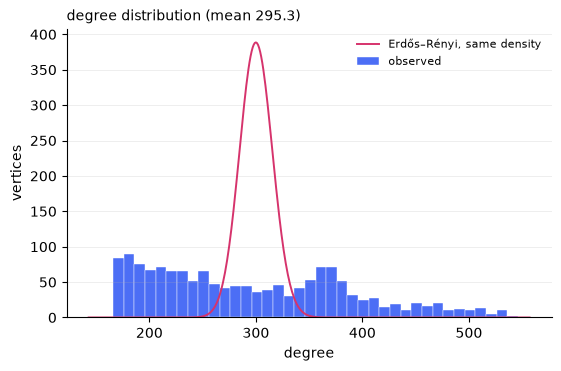

In [54]:
viz.plot_degree_distribution(ss.generate("power", 1500, 0.2, seed=52));

## Formats and other libraries

Graphs read and write graph6, sparse6, Matrix Market, edge lists, DOT and GraphML, and convert to and
from networkx, igraph, SciPy and NumPy.

In [55]:
path = pathlib.Path(tempfile.mkdtemp()) / "g.g6"
g.write(path)
assert ss.read(path) == g
print(convert.to_networkx(g), "|", repr(convert.to_scipy(g)))
print("formats:", ss.formats())

Graph with 100 nodes and 2969 edges | <Compressed Sparse Row sparse array of dtype 'int8'
	with 5938 stored elements and shape (100, 100)>
formats: {'lists': True, 'edgelist': True, 'graph6': True, 'sparse6': True, 'mtx': True, 'dot': False, 'graphml': False, 'wlists': True}
